---
title: Multi-Armed Bandit problem with Active Inference
subtitle: Using PyMDP to solve a 2-armed MAB problem with an epistemic twist
author: Kobus Esterhuysen
date: '2025-04-06'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - Probabilistic Programming
  - PyMDP
  - Python
image: MAB-with-AIF.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [61]:
#| hide
# BASED ON
    # MAB-with-AIF_PORT^v3.ipynb
    # MAB-with-AIF_PORT^v2.ipynb
    # MAB-with-AIF_PORT^v1.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v10.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v9.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v8.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v6.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v5.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v4.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v3.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v2.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v1.ipynb
    # Active_Inference_with_pymdp_Tutorial_2.ipynb

# DONE
# v1 starts ------------------------------------------------
# num --> car for cardinality
# obs --> obser
# control --> contr
# underscores before globals
# make names on graphics the same as names in the code
    # organization of graphics don't seem to match that of the code
    # maybe remove the graphics
# v2 starts ------------------------------------------------
# v3 starts ------------------------------------------------
# add _lab to convert between labels and indices
# v4 starts ------------------------------------------------
# have 0-indexed factors & modalities
# remove def get_model_dimensions_from_labels()
    # manually define cardinalities
# add labels for plot_likelihood
# v5 starts ------------------------------------------------
# v6 starts ------------------------------------------------
# change _lab to _lup in all projects
    # lookup between indexes & labels
# remove highest level in _lab
    # BUT, won't be able to then use utils.get_model_dimensions_from_labels(_model_labels)
# car -> dims (plural) (after all the car's are the dimensions)
# v8 starts ------------------------------------------------
# align with KUF framework (i.e. modified CRISP-DM)
# use math symbols in class ThreeArmedBanditEnvir(object)
# add reset() for class ThreeArmedBanditEnvir(object)
# rename to something like 3-arm MAB before making _PORT post
# plot vars against time
# v9 starts ------------------------------------------------
# add optional labels for def plot_beliefs(belief_dist, title_str="")
# add optional labels for def plot_likelihood(belief_dist, title_str="")
# plot qIsI
# plot qIpiI
# plot EFE
# add def get_policy_labels(policies) to have text ticklabels
# fixed-width font for vertical plot_beliefs()
    # had to install first in Dockerfile
# replace 'Do-Nothing' with 'Null'
    # will make labels less unwieldy
# remove q(s) plots from 'dot graphs'
# v10 starts ------------------------------------------------
# clean

# v1 starts ------------------------------------------------
# rename ThreeArmedBanditEnvir(object) to EpistemicMABEnvir(object)
# update narrative
    # refactoring of pymdp tutorial 2
    # used as stepping stone for project on AIF schedule agent
    # serves as base for a project
    # KUF used
# publish
# v2 starts ------------------------------------------------
# rename efe to EFE
# rename _GNegs to _EFE
# rename plot_efe() to plot_FE()
# rename qIsI to QIsI
# rename policy_len to H for time horizon
# v3 starts ------------------------------------------------
# remove index subscripts from names of facs & mods
    # reduce confusion when adding/removing a fac/mod
    # hierarchical facs/mods already makes the indexes non-relevant
# update narrative
    # remove subscripts from narrative
    # change sequence of mods/facs in narrative to have the same sequence in _lup
# v4 starts ------------------------------------------------
# have a dynamic sContext, preconfigured by a list

# TODO
# change
    # "aChoice": ['Move-Start', 'Get-Hint', 'Play-Left', 'Play-Right'],
    # to
    # "aAssign": ['Assign-Start', 'Assign-Hint', 'Assign-Left', 'Assign-Right'],
# change
    # "sChoice": ['Start', 'Hint', 'Left', 'Right'],
    # to
    # "sAssigned": ['Start', 'Hint', 'Left', 'Right'],
# change
    # "s̆Choice": ['Start', 'Hint', 'Left', 'Right'],
    # to
    # "s̆Assigned": ['Start', 'Hint', 'Left', 'Right'],
# change
    # "sContext": ['Left-Better', 'Right-Better'],
    # to
    # "sAvail": ['Left-Better', 'Right-Better'],
# change
    # "s̆Context": ['Left-Better', 'Right-Better'],
    # to
    # "s̆Avail": ['Left-Better', 'Right-Better'],
# change
    # "oChoice": ['Start', 'Hint', 'Left', 'Right'],
    # to
    # "oAssigned": ['Start', 'Hint', 'Left', 'Right'],

# plot VFE


In this project we refactor one of the PyMDP examples to serve as a baseline for a future client project. Here are some of the changes:

- add a lookup table `_lup` to lookup a value/level
    - label, given the index
    - index, given the label
- use zero-based factors and modalities to align better with Python's convention
- plot variables against time
- add `get_policy_labels(policies)` to provide text tick labels (rather than indexes) in distribution bar plots

A few coding conventions:

- Global variable names usually start with an underscore, i.e. _
- This notebook follows a standardized framework. This is my own framework, developed over a number of years, and is informed by the CRISP-DM framework, the work of Warren Powell (Princeton), the work of Bert De Vries, the work of Karl Friston as well as that of the larger Active Inference community.


In [62]:
! python --version
import sys
!{sys.executable} -m pip list | grep inferactively-pymdp

Python 3.10.12
inferactively-pymdp           0.0.7.1

[notice] A new release of pip is available: 23.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


In [63]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymdp
from pymdp import utils
from pymdp.agent import Agent
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import math
import random

### Define some utilities

In [64]:
def plot_likelihood(
  matrix, ## conditional distribution
  title_str="Likelihood distribution (A)",
  xlabels=None, 
  ylabels=None,
  size=None):   
    """
    Plots a 2-D likelihood matrix as a heatmap
    """
    if not np.isclose(matrix.sum(axis=0), 1.0).all():
      raise ValueError("Distribution not column-normalized! Please normalize (ensure matrix.sum(axis=0) == 1.0 for all columns)")
    if size == None:
      fig = plt.figure(figsize = (5,5))
    else:
      fig = plt.figure(figsize = size)

    ## fig = plt.figure(figsize = (6,6))
    fig = plt.figure(figsize = size)

    if ylabels == None and xlabels == None: 
        sns.heatmap(
            matrix, 
            cmap='OrRd', 
            linewidths=1,
            cbar=True, 
            vmin=0.0, 
            vmax=1.0)
    else:
        ax = sns.heatmap(
            matrix, 
            xticklabels = xlabels, 
            yticklabels = ylabels, 
            ## cmap = 'gray', 
            cmap = "OrRd",
            linewidths=1,
            cbar = True,
            square=True,
            vmin = 0.0, 
            vmax = 1.0)
    plt.title(title_str)
    plt.show()

def plot_beliefs(
    vector, ## belief distribution
    title_str="",
    xlabels=None,
    size=None): 
    """
    Plot a categorical distribution or belief distribution, stored in the 1-D numpy vector `vector`
    """
    if not np.isclose(vector.sum(), 1.0):
      raise ValueError("Distribution not normalized! Please normalize")
    if size == None:
      fig = plt.figure(figsize = (1,1))
    else:
      fig = plt.figure(figsize = size)
    plt.grid(zorder=0)
    plt.bar(range(vector.shape[0]), vector, color='r', zorder=3)
    if xlabels == None: 
      plt.xticks(range(vector.shape[0]))
    else:
      ##+ plt.xticks(range(len(xlabels)), xlabels, rotation='vertical', fontname='DejaVu Sans Mono') ##.fixed-width font
      plt.xticks(range(len(xlabels)), xlabels, rotation='vertical', fontname='Liberation Mono') ##.fixed-width font
    plt.title(title_str)
    plt.show()

def plot_FE(
    vector, 
    title_str="",
    xlabels=None,
    size=None): 
    if size == None:
      fig = plt.figure(figsize = (1,1))
    else:
      fig = plt.figure(figsize = size)
    plt.grid(zorder=0)
    plt.bar(range(vector.shape[0]), vector, color='r', zorder=3)
    if xlabels == None: 
      plt.xticks(range(vector.shape[0]))
    else:
      plt.xticks(range(len(xlabels)), xlabels, rotation='vertical')
    plt.title(title_str)
    plt.show()

_lup = { ## lookup between indexes & labels
    ## control/action factors
    "aChoice": [
    # "aAssign": [ ## assign to this play
        'Move-Start', 'Get-Hint', 'Play-Left', 'Play-Right'],
        # 'Assign-Start', 'Assign-Hint', 'Assign-Left', 'Assign-Right'],
    "aNull": [ 
        'Null'], ## 'Null'; sContext uncontrollable

    ## state factors
    "sChoice": [
        'Start', 'Hint', 'Left', 'Right'],
    "sContext": [ ## uncontrollable (exog info)
    # "sAvail": [ ## uncontrollable (exog info); avail to provide reward
        'Left-Better', 'Right-Better'],

    "s̆Choice": [
        'Start', 'Hint', 'Left', 'Right'],
    "s̆Context": [ ## uncontrollable (exog info)
        'Left-Better', 'Right-Better'],

    ## observation modalities
    "oChoice": [
        'Start', ## Move-start played
        'Hint', ## Get-hint played
        'Left', ## Play-left played
        'Right' ## Play-right played
    ],
    "oHint": [
        'Null', ## Hint not played
        'Hint-Left', ## Hint said left
        'Hint-Right' ## Hint said right
    ],
    "oRew": [
        'Null', 'Loss', 'Reward'],
}    

# 1 BUSINESS UNDERSTANDING

The current problem involves an explore/exploit task with an epistemic two-armed bandit. The [multi-armed bandit](https://en.wikipedia.org/wiki/Multi-armed_bandit) (or MAB) is a classic decision-making task that captures the core features of the "explore/exploit tradeoff". The multi-armed bandit formulation is ubiquitous across problem spaces that require sequential decision-making under uncertainty -- this includes disciplines ranging from economics, neuroscience, machine learning, engineering all the way to advertising.

In the standard MAB problem formulation, an agent must choose between mutually-exclusive alternatives (also known as 'arms') in order to maximize reward over time. The probability of reward depends on which arm the agent chooses. A common real-world analogy for a MAB problem is imagining a special slot machine with three possible levers to pull (rather than the usual one), where playing each lever has different probabilities of payoff (e.g. getting a winning combination of symbols or bonus). In fact, the 'standard' slot machine, which usually only has one lever, was historically referred to as a 'one-armed bandit' -- this was the direct ancestor of the name for the generic machine learning / decision-making problem class, the MAB.

Crucially, MAB problems are interesting and difficult because in general, the reward statistics of each arm are unknown or only partially known. In a probabilistic or Bayesian context, an agent must therefore act based on _beliefs_ about the reward statistics, since they don't have perfect access to this information.

The inherent partial-observability  of the task creates a conflict between **exploitation** or choosing the arm that is _currently believed_ to be most rewarding, and **exploration** or gathering information about the remaining arms, in the hopes of discovering a potentially more rewarding option.

The fact that expected reward or utility is contextualized by _beliefs_ -- i.e. which arm is currently thought to be the most rewarding -- motivates the use of active inference in this context. This is because the key objective function for action-selection, the expected free energy $\mathbf{G}$, depends on the agent's beliefs about the world. And not only that, but expected free energy balances the desire to maximize rewards with the drive to resolve uncertainty about unknown parts of the agent's model. The more accurate the agent's beliefs are, the more faithfully decision-making can be guided by maximizing expected utility or rewards.

#### **MAB with an epistemic twist**

In the MAB formulation we'll be exploring in this problem, the agent must choose to play among two possible arms, each of which has unknown reward statistics. These reward statistics take the form of Bernoulli distributions over two possible reward outcomes: "Loss" and "Reward". However, one of the arms has probability $p$ of yielding "Reward"" and probabiliity $(1-p)$ of yielding "Loss". The other arm has swapped statistics. In this example, the agent knows that the bandit has this general reward structure, except they don't know *which* of the two arms is the rewarding one (the arm where reward probability is $p$, assuming $p \in [0.5, 1]$).

However, we introduce an additional feature in the environment, that induces an explicit trade-off in decision-making between exploration (information-seeking) and exploitation (reward-seeking). In this special "epistemic bandit" problem, there is an additional action available to the agent, besides playing the two arms. We call this third action "Get Hint", and allows the agent to acquire information that reveals (potentially probabilistically) which arm is the more rewarding one. There is a trade-off here, because by choosing to acquire the hint, the agent forgoes the possibility of playing an arm and thus the possibility of getting a reward at that moment. The mutual exclusivity of hint-acquisition and arm-playing imbues the system with an explore/exploit trade-off, which active inference is particularly equipped to handle, when compared to simple reinforcement learning schemes (e.g. epsilon-greedy reward maximization).


In [65]:
##. Visualize: 3 levers, button in the center (Move-Start) 

## Play-Left              Play-Right
##            Move-Start
##             Get-Hint

# 2 DATA UNDERSTANDING

There is no pre-existing data to be analyzed.

# 3 DATA PREPARATION

There is no pre-existing data to be prepared.

# 4 MODELING

## 4.1 Narrative

Please review the narrative in section 1.

## 4.2 Core Elements

This section attempts to answer three important questions:

- What metrics are we going to track?
- What decisions do we intend to make?
- What are the sources of uncertainty?

For this problem, the main metric we are interested in is the probability of observing a `Reward`. In addition, we want to keep track of what the hint lever reveals as well as the choices played by the agent.

The only source of uncertainty is which lever is more profitable to play: left or right.

## 4.3 System-Under-Steer / Environment / Generative Process

### 4.3.1 State variables

The state at time $t$ of the system-under-steer/environment (`envir`) is given by 

$$
\begin{aligned}
\breve{\mathbf{s}}_t &= (\breve{s}^{\mathrm{Choice}}_{t}, \breve{s}^{\mathrm{Context}}_{t} )
\end{aligned}
$$
where

- $\breve{s}^{\mathrm{Choice}}_{t} \in \{\text{Start}, \text{Hint}, \text{Left}, \text{Right}\}$
- $\breve{s}^{\mathrm{Context}}_{t} \in \{\text{Left-Better}, \text{Right-Better}\}$

### 4.3.2 Decision variables

The *decision variables* represent *what we control*.

The environment is steered by decisions/actions $\mathbf{a}_t$. Each component of this vector is called a *control factor* or *control state factor*. The action at time $t$ is given by

$$
\begin{aligned}
\mathbf{a}_t &= (a^{\mathrm{Choice}}_{t}, a^{\mathrm{Null}}_{t} )
\end{aligned}
$$
where

- $a^{\mathrm{Choice}}_{t} \in \{\text{Move-Start}, \text{Get-Hint}, \text{Play-Left}, \text{Play-Right}\}$
- $a^{\mathrm{Null}}_{t} \in \{\text{Null}\}$


### 4.3.3 Exogenous information variables

The exogenous information is not controllable by the agent. It is captured in the state factor 
$$\breve{s}^{\mathrm{Context}}_{t} \in \{\text{Left-Better}, \text{Right-Better}\}$$



### 4.3.4 Next State

To find the *next state* for each time step, the generative process starts with the *transition function* $f$. To this is added exogenous information and system noise to arrive at the next state.

### 4.3.5 Observation

To find the *observation* generated by the external state of the generative process for each time step, the generative process starts with the *generating function* $g$. To this is added observation or measurement noise to arrive at the observation.

### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

We assume that the reality of the generative process is given by the following implementation:

In [66]:
# _lup['s̆Context'][utils.sample(np.array([0.5, 0.5]))]
# [int(utils.sample(np.array([0.5, 0.5]))) for i in range(5)]
[_lup['s̆Context'][utils.sample(np.array([0.5, 0.5]))] for i in range(5)]

['Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better']

In [67]:
class EpistemicMABEnvir(object):
  # def __init__(self, context=None, p_hint=None, p_reward=None):
  def __init__(self, contexts=None, p_hint=None, p_reward=None):
    if contexts == None:
      ## randomly sample which bandit arm is better (Left or Right):
      # self.s̆Context = _lup['s̆Context'][utils.sample(np.array([0.5, 0.5]))]
      self.s̆Context = [_lup['s̆Context'][utils.sample(np.array([0.5, 0.5]))] for i in range(2)]
    else:
      self.s̆Context = contexts
    if p_hint == None:
      self.p_hint = 1.0
    else:
      self.p_hint = p_hint
    if p_reward == None:
      self.p_reward = 0.8
    else:
      self.p_reward = p_reward

  # def step(self, action):
  def step(self, t, action):
    print(f"=== step('{action}')")
    if action == "Move-Start":
      oHint = "Null"
      oRew = "Null"
      oChoice = "Start"
    elif action == "Get-Hint":
      # if self.s̆Context == "Left-Better":
      if self.s̆Context[t] == "Left-Better":
        oHint = _lup['oHint'][utils.sample(np.array([0.0, self.p_hint, 1.0 - self.p_hint]))]
      # elif self.s̆Context == "Right-Better":
      elif self.s̆Context[t] == "Right-Better":
        oHint = _lup['oHint'][utils.sample(np.array([0.0, 1.0 - self.p_hint, self.p_hint]))]
      # else: print(f'ERROR: Invalid self.s̆Context: {self.s̆Context}')
      else: print(f'ERROR: Invalid self.s̆Context: {self.s̆Context[t]}')
      oRew = "Null"
      oChoice = "Hint"
    elif action == "Play-Left":
      oHint = "Null"
      oChoice = "Left"
      # if self.s̆Context == "Left-Better":
      if self.s̆Context[t] == "Left-Better":
        oRew = _lup['oRew'][utils.sample(np.array([0.0, 1.0 - self.p_reward, self.p_reward]))]
      # elif self.s̆Context == "Right-Better":
      elif self.s̆Context[t] == "Right-Better":
        oRew = _lup['oRew'][utils.sample(np.array([0.0, self.p_reward, 1.0 - self.p_reward]))]
      # else: print(f'ERROR: Invalid self.s̆Context: {self.s̆Context}')
      else: print(f'ERROR: Invalid self.s̆Context: {self.s̆Context[t]}')
    elif action == "Play-Right":
      oHint = "Null"
      oChoice = "Right"
      # if self.s̆Context == "Right-Better":
      if self.s̆Context[t] == "Right-Better":
        oRew = _lup['oRew'][utils.sample(np.array([0.0, 1.0 - self.p_reward, self.p_reward]))]
      # elif self.s̆Context == "Left-Better":
      elif self.s̆Context[t] == "Left-Better":
        oRew = _lup['oRew'][utils.sample(np.array([0.0, self.p_reward, 1.0 - self.p_reward]))]
      # else: print(f'ERROR: Invalid self.s̆Context: {self.s̆Context}')
      else: print(f'ERROR: Invalid self.s̆Context: {self.s̆Context[t]}')
    else: print(f'ERROR: Invalid action: {action}')
    obs = [oChoice, oHint, oRew]
    return obs

  def reset(self):
    ## self.s̆Context = _lup['s̆Context'][utils.sample(np.array([0.5, 0.5]))]
    print(f'Re-initialized to:\n{self.s̆Context=}\n{self.p_hint=}\n{self.p_reward=}')
    oChoice = "Start"
    oHint = "Null"
    oRew = "Null"
    print(f'{oChoice=}, {oHint=}, {oRew=}')
    return oChoice, oHint, oRew

Give this environment class a quick test drive:

In [68]:
contexts = [
    'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    'Right-Better', 'Right-Better',
]
_envir = EpistemicMABEnvir(contexts=contexts)
# _envir = EpistemicMABEnvir()
_envir

In [69]:
_envir.reset()

Re-initialized to:
self.s̆Context=['Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better']
self.p_hint=1.0
self.p_reward=0.8
oChoice='Start', oHint='Null', oRew='Null'


('Start', 'Null', 'Null')

In [70]:
# _envir.step('Play-Left')
_envir.step(0, 'Play-Left')

=== step('Play-Left')


['Left', 'Null', 'Reward']

## 4.4 Uncertainty Model

The uncertainty of which side is better to play is provided for in the `__init__()` function of `class EpistemicMABEnvir()` when `context= None`.

## 4.5 Agent / Generative Model

Specify the dimensionalities of the hidden state factors, the control state factors, and the observation modalities:

In [71]:
## dimensionalities/cardinalities
##   define by manually inspecting _lup
_a_dims = [4, 1]; print(f'{_a_dims=}') ## sContext uncontrollable
_s_dims = [4, 2]; print(f'{_s_dims=}')
_o_dims = [4, 3, 3]; print(f'{_o_dims=}')

_a_dims=[4, 1]
_s_dims=[4, 2]
_o_dims=[4, 3, 3]


### 4.5.1 State variables

According to the agent the state of the system-under-steer/environment/generative process will be $\mathbf{s}_t$, rather than $\mathbf{\breve s}_t$. It is given by 

$$
\begin{aligned}
\mathbf{s}_t &= (s^{\mathrm{Choice}}_{t}, s^{\mathrm{Context}}_{t})
\end{aligned}
$$
where

- $s^{\mathrm{Choice}}_{t} \in \{\text{Start}, \text{Hint}, \text{Left}, \text{Right}\}$
- $s^{\mathrm{Context}}_{t} \in \{\text{Left-Better}, \text{Right-Better}\}$

### 4.5.2 Decision variables

According to the agent the action on the environment at time $t$ will be represented by $\mathbf{u}_t$, also known as the control state of the agent.

### 4.5.3 Implementation of the Agent / Generative Model / Internal Model

#### 4.5.3.1 Observation likelihood matrix, $\mathbf A$ or $P(o_t\mid s_t)$

In [72]:
print(_s_dims)
print(_o_dims)

[4, 2]
[4, 3, 3]


In [73]:
_A_shapes = [[o_dim] + _s_dims for o_dim in _o_dims]
_A_shapes

[[4, 4, 2], [3, 4, 2], [3, 4, 2]]

In [74]:
_A = utils.obj_array_zeros(_A_shapes)
_A

array([array([[[0., 0.],
               [0., 0.],
               [0., 0.],
               [0., 0.]],

              [[0., 0.],
               [0., 0.],
               [0., 0.],
               [0., 0.]],

              [[0., 0.],
               [0., 0.],
               [0., 0.],
               [0., 0.]],

              [[0., 0.],
               [0., 0.],
               [0., 0.],
               [0., 0.]]]), array([[[0., 0.],
                                    [0., 0.],
                                    [0., 0.],
                                    [0., 0.]],

                                   [[0., 0.],
                                    [0., 0.],
                                    [0., 0.],
                                    [0., 0.]],

                                   [[0., 0.],
                                    [0., 0.],
                                    [0., 0.],
                                    [0., 0.]]]), array([[[0., 0.],
                                          

##### Observation Modality $o^{\mathrm{Choice}}$

##### A[m] or $P(o^{\mathrm{Choice}}_{t}\mid \mathbf{s}_t)$

In [76]:
m = 0
for s_idx in range(len(_lup['sChoice'])):
  _A[m][s_idx, s_idx, :] = 1.0

print(_A[m].shape)
_A[m]
## 4 matrices of 4x2

(4, 4, 2)


array([[[1., 1.],
        [0., 0.],
        [0., 0.],
        [0., 0.]],

       [[0., 0.],
        [1., 1.],
        [0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.],
        [1., 1.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.],
        [0., 0.],
        [1., 1.]]])

In [77]:
utils.is_normalized(_A[m])

True

<Figure size 500x500 with 0 Axes>

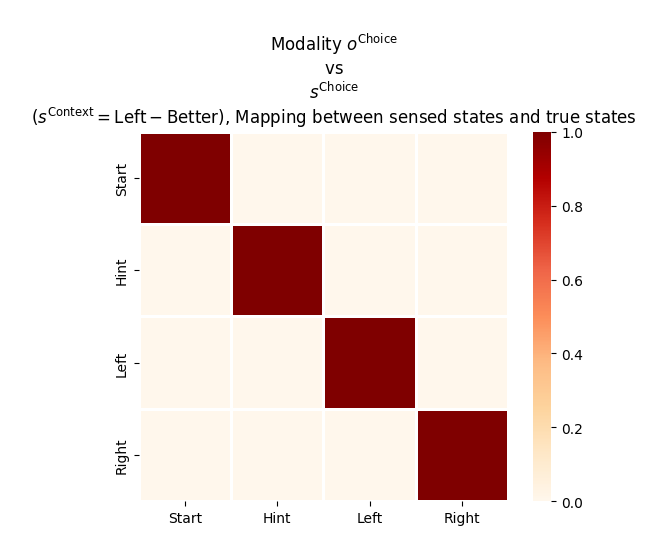

In [78]:
"""
Condition on context (first hidden state factor) and display the remaining 
indices (outcome and choice state) 
"""
plot_likelihood(
    _A[m][:,:,0], 
    title_str="""
    Modality $o^{\mathrm{Choice}}$
    vs
    $s^{\mathrm{Choice}}$
    ($s^{\mathrm{Context}}=\mathrm{Left-Better}$), Mapping between sensed states and true states""",
    ylabels=_lup['oChoice'],
    xlabels=_lup['sChoice'],
)

##### Observation Modality $o^{\mathrm{Hint}}$

##### A[m] or $P(o^{\mathrm{Hint}}_{t}\mid \mathbf{s}_t)$

In [22]:
## accuracy of the hint, according to the agent's generative model (how much does 
##  the agent trust the hint?)
m = 1
## _p_hint = 0.7 
_p_hint = 1.0 
for s_idx, s_lab in enumerate(_lup['sChoice']):
  if s_lab == 'Start':
    _A[m][0, s_idx, :] = 1.0
  elif s_lab == 'Hint':
    _A[m][1, s_idx, :] = np.array([_p_hint,       1.0 - _p_hint])
    _A[m][2, s_idx, :] = np.array([1.0 - _p_hint, _p_hint])
  elif s_lab == 'Left':
    _A[m][0, s_idx, :] = 1.0
  elif s_lab == 'Right':
    _A[m][0, s_idx, :] = 1.0
    
_A[m]
## 3 matrices of 4x2

array([[[1., 1.],
        [0., 0.],
        [1., 1.],
        [1., 1.]],

       [[0., 0.],
        [1., 0.],
        [0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 1.],
        [0., 0.],
        [0., 0.]]])

In [23]:
utils.is_normalized(_A[m])

True

<Figure size 500x500 with 0 Axes>

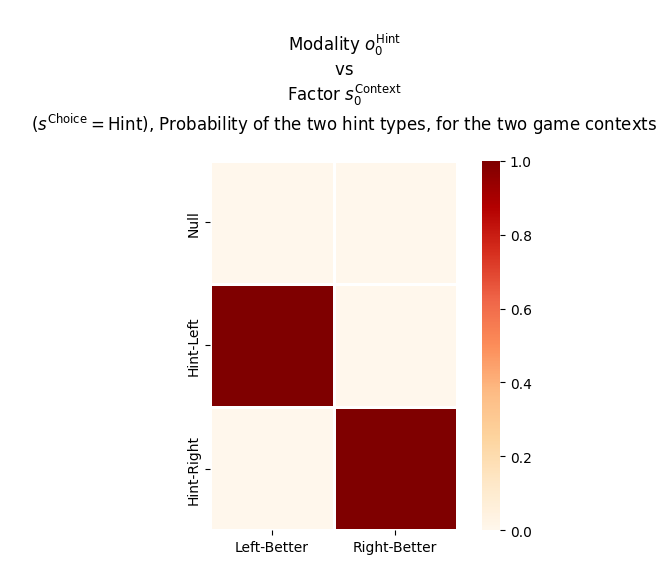

In [24]:
plot_likelihood(
    _A[m][:,1,:], 
    title_str="""
    Modality $o^{\mathrm{Hint}}_0$
    vs
    Factor $s^{\mathrm{Context}}_0$
    ($s^{\mathrm{Choice}}=\mathrm{Hint}$), Probability of the two hint types, for the two game contexts
    """,
    ylabels=_lup['oHint'],
    xlabels=_lup['sContext']
)


##### Observation Modality $o^{\mathrm{Rew}}$


##### A[m] or $P(o^{\mathrm{Rew}}_{t}\mid \mathbf{s}_t)$

In [25]:
## _p_reward = 0.8 ## probability of getting a rewarding outcome, if you are sampling the more rewarding bandit
_p_reward = 1.0 ## probability of getting a rewarding outcome, if you are sampling the more rewarding bandit
m = 2
for s1_idx, s1_nam in enumerate(_lup['sChoice']):
  if s1_nam == 'Start':
    _A[m][0, s1_idx, :] = 1.0
  elif s1_nam == 'Hint':
    _A[m][0, s1_idx, :] = 1.0
  elif s1_nam == 'Left':
    _A[m][1:, s1_idx, :] = np.array([ [1.0-_p_reward, _p_reward],
                                      [_p_reward,     1.0-_p_reward] ])
  elif s1_nam == 'Right':
    _A[m][1:, s1_idx, :] = np.array([ [ _p_reward,   1.0- _p_reward],
                                      [1-_p_reward,  _p_reward] ])
    
_A[m]
## 3 matrices of 4x2

array([[[1., 1.],
        [1., 1.],
        [0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.],
        [0., 1.],
        [1., 0.]],

       [[0., 0.],
        [0., 0.],
        [1., 0.],
        [0., 1.]]])

In [26]:
utils.is_normalized(_A[m])

True

<Figure size 500x500 with 0 Axes>

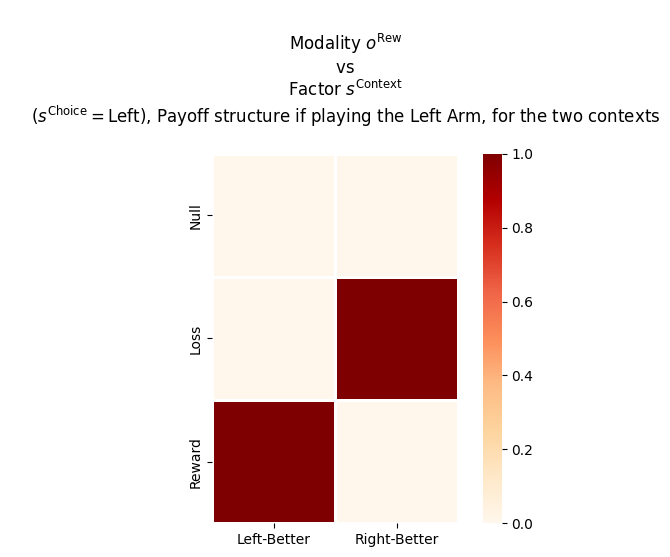

In [27]:
plot_likelihood(
    _A[m][:,2, :], 
    title_str="""
    Modality $o^{\mathrm{Rew}}$
    vs
    Factor $s^{\mathrm{Context}}$
    ($s^{\mathrm{Choice}}=\mathrm{Left}$), Payoff structure if playing the Left Arm, for the two contexts
    """,
    ylabels=_lup['oRew'],
    xlabels=_lup['sContext']
)

In [28]:
utils.is_normalized(_A)

True

In [29]:
print(f'=== _s_dims:\n{_s_dims}')
print(f'=== _o_dims:\n{_o_dims}')
## _A

=== _s_dims:
[4, 2]
=== _o_dims:
[4, 3, 3]


#### 4.5.3.2 Transition likelihood matrix, $\mathbf B$ or $P(s_{t}\mid s_{t-1}, u_{t-1})$

In [30]:
print(_a_dims)
print(_s_dims)

[4, 1]
[4, 2]


In [31]:
_B_shapes = [[s_dim, s_dim, _a_dims[f]] for f,s_dim in enumerate(_s_dims)]
_B_shapes

[[4, 4, 4], [2, 2, 1]]

In [32]:
_B = utils.obj_array_zeros(_B_shapes)
_B
## 4 matrices of 4x4
## 2 matrices of 2x1

array([array([[[0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.]],

              [[0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.]],

              [[0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.]],

              [[0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.],
               [0., 0., 0., 0.]]]), array([[[0.],
                                            [0.]],

                                           [[0.],
                                            [0.]]])], dtype=object)

##### State Factor $s^{\mathrm{Choice}}$

##### B[f] or $P(s^{\mathrm{Choice}}_t\mid s^{\mathrm{Choice}}_{t-1}, a^{\mathrm{Choice}}_{t-1})$

In [33]:
f = 0
for s_idx in range(len(_lup['sChoice'])):
  _B[f][s_idx, :, s_idx] = 1.0
_B[f]
## 4 matrices of 4x4

array([[[1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.]],

       [[0., 1., 0., 0.],
        [0., 1., 0., 0.],
        [0., 1., 0., 0.],
        [0., 1., 0., 0.]],

       [[0., 0., 1., 0.],
        [0., 0., 1., 0.],
        [0., 0., 1., 0.],
        [0., 0., 1., 0.]],

       [[0., 0., 0., 1.],
        [0., 0., 0., 1.],
        [0., 0., 0., 1.],
        [0., 0., 0., 1.]]])

In [34]:
utils.is_normalized(_B[f])

True

<Figure size 500x500 with 0 Axes>

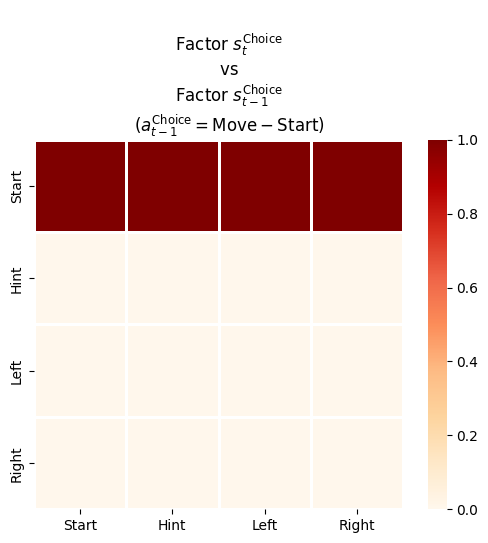

In [35]:
plot_likelihood(
    _B[f][:,:,_lup['aChoice'].index('Move-Start')],
    title_str="""
    Factor $s^{\mathrm{Choice}}_{t}$
    vs
    Factor $s^{\mathrm{Choice}}_{t-1}$
    ($a^{\mathrm{Choice}}_{t-1}=\mathrm{Move-Start}$)""",
    ylabels=_lup['sChoice'],
    xlabels=_lup['sChoice'],
)

<Figure size 500x500 with 0 Axes>

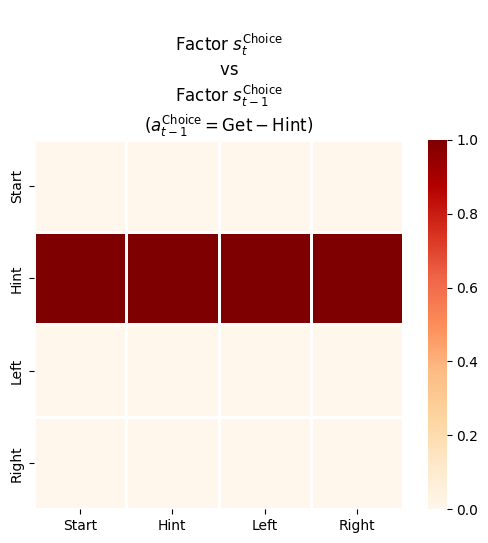

In [36]:
plot_likelihood(
    _B[f][:,:,_lup['aChoice'].index('Get-Hint')],
    title_str="""
    Factor $s^{\mathrm{Choice}}_{t}$
    vs
    Factor $s^{\mathrm{Choice}}_{t-1}$
    ($a^{\mathrm{Choice}}_{t-1}=\mathrm{Get-Hint}$)""",
    ylabels=_lup['sChoice'],
    xlabels=_lup['sChoice'],
)

<Figure size 500x500 with 0 Axes>

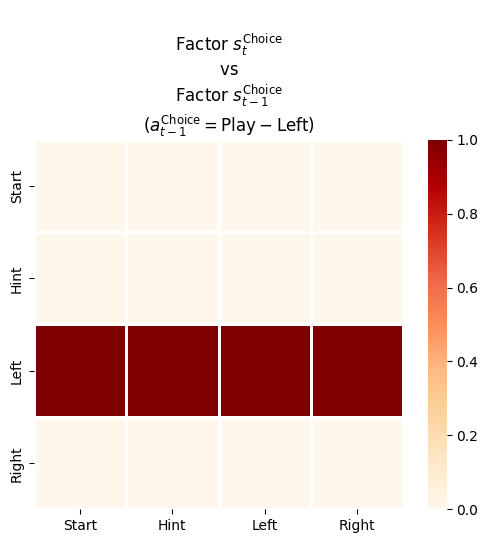

In [37]:
plot_likelihood(
    _B[f][:,:,_lup['aChoice'].index('Play-Left')],
    title_str="""
    Factor $s^{\mathrm{Choice}}_{t}$
    vs
    Factor $s^{\mathrm{Choice}}_{t-1}$
    ($a^{\mathrm{Choice}}_{t-1}=\mathrm{Play-Left}$)""",
    ylabels=_lup['sChoice'],
    xlabels=_lup['sChoice'],
)

<Figure size 500x500 with 0 Axes>

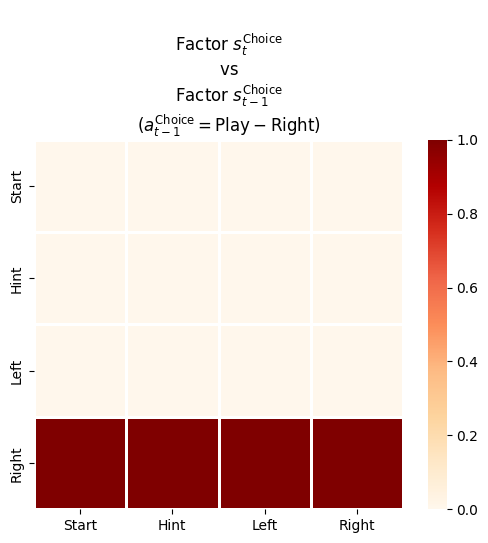

In [38]:
plot_likelihood(
    _B[f][:,:,_lup['aChoice'].index('Play-Right')],
    title_str="""
    Factor $s^{\mathrm{Choice}}_{t}$
    vs
    Factor $s^{\mathrm{Choice}}_{t-1}$
    ($a^{\mathrm{Choice}}_{t-1}=\mathrm{Play-Right}$)""",
    ylabels=_lup['sChoice'],
    xlabels=_lup['sChoice'],
)

##### State factor $s^{\mathrm{Context}}$

##### B[f] or $P(s^{\mathrm{Context}}_t\mid s^{\mathrm{Context}}_{t-1}, a^{\mathrm{Choice}}_{t-1})$

In [39]:
f = 1
_B[f][:,:,0] = np.eye(len(_lup['sContext']))
_B[f]

array([[[1.],
        [0.]],

       [[0.],
        [1.]]])

In [40]:
utils.is_normalized(_B[f])

True

<Figure size 500x500 with 0 Axes>

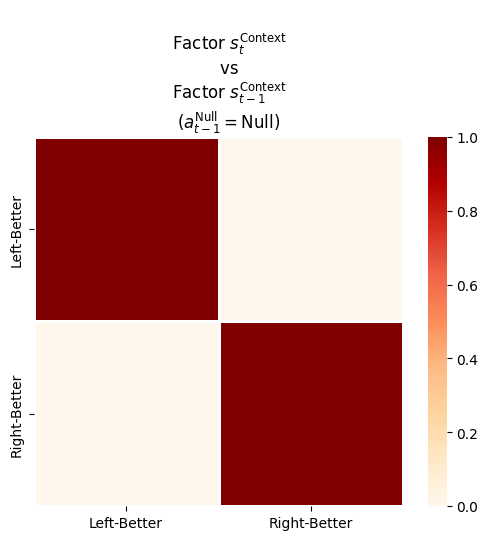

In [41]:
plot_likelihood(
    _B[f][:,:,_lup['aNull'].index('Null')],
    title_str="""
    Factor $s^{\mathrm{Context}}_{t}$
    vs
    Factor $s^{\mathrm{Context}}_{t-1}$
    ($a^{\mathrm{Null}}_{t-1}=\mathrm{Null}$)""",
    ylabels=_lup['sContext'],
    xlabels=_lup['sContext'],
)

In [42]:
print(f'=== _a_dims:\n{_a_dims}')
print(f'=== _s_dims:\n{_s_dims}')
_B

=== _a_dims:
[4, 1]
=== _s_dims:
[4, 2]


array([array([[[1., 0., 0., 0.],
               [1., 0., 0., 0.],
               [1., 0., 0., 0.],
               [1., 0., 0., 0.]],

              [[0., 1., 0., 0.],
               [0., 1., 0., 0.],
               [0., 1., 0., 0.],
               [0., 1., 0., 0.]],

              [[0., 0., 1., 0.],
               [0., 0., 1., 0.],
               [0., 0., 1., 0.],
               [0., 0., 1., 0.]],

              [[0., 0., 0., 1.],
               [0., 0., 0., 1.],
               [0., 0., 0., 1.],
               [0., 0., 0., 1.]]]), array([[[1.],
                                            [0.]],

                                           [[0.],
                                            [1.]]])], dtype=object)

In [43]:
utils.is_normalized(_B)

True

#### 4.5.3.3 Prior preferences, $\mathbf C$ (the C vectors)

In [44]:
print(_o_dims)

[4, 3, 3]


In [45]:
## For C, each observation modality has a VECTOR, NOT a MATRIX as in the case of A
_C = utils.obj_array_zeros(_o_dims) ##.
_C

array([array([0., 0., 0., 0.]), array([0., 0., 0.]), array([0., 0., 0.])],
      dtype=object)

In [46]:
## leave _C[0]

## leave _C[1]

_C[2][1] = -4.0 ##. do not want to see the oRew == 'Loss' observation
# _C[2][2] = 2.0 ##. want to see the oRew == 'Reward' observation 
_C[2][2] = 4.0 ##. want to see the oRew == 'Reward' observation 

_C

array([array([0., 0., 0., 0.]), array([0., 0., 0.]),
       array([ 0., -4.,  4.])], dtype=object)

In [47]:
from pymdp.maths import softmax
softmax(_C[2])

array([1.79802867e-02, 3.29320439e-04, 9.81690393e-01])

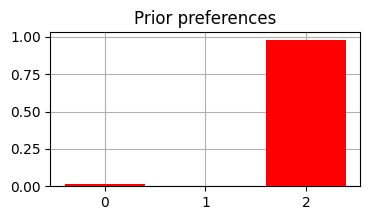

In [48]:
plot_beliefs(softmax(_C[2]), title_str="Prior preferences", size=(4,2))

#### 4.5.3.4 Prior over (initial) hidden states, $\mathbf D$ (the D vectors)

In [49]:
print(_s_dims)

[4, 2]


In [50]:
## For D, each state factor has a VECTOR, NOT a MATRIX as in the case of B
_D = utils.obj_array_zeros(_s_dims)
_D

array([array([0., 0., 0., 0.]), array([0., 0.])], dtype=object)

In [51]:
## _D[0] = [0.5, 0.5] ## breaks later, has to be np.array()
_D[0] = np.array([1.0, 0.0, 0.0, 0.0]) ##. certain about 'Start'
_D

array([array([1., 0., 0., 0.]), array([0., 0.])], dtype=object)

In [52]:
## _D[1] = [1.0, 0.0, 0.0, 0.0] ## breaks later, has to be np.array()
_D[1] = np.array([0.5, 0.5])
_D

array([array([1., 0., 0., 0.]), array([0.5, 0.5])], dtype=object)

In [53]:
print(f'Beliefs about starting location: {_D[0]}')
print(f'Beliefs about which arm is better: {_D[1]}')

Beliefs about starting location: [1. 0. 0. 0.]
Beliefs about which arm is better: [0.5 0.5]


## 4.6 Active Inference / Agent Evaluation

Now we'll write a function that will take the agent, the environment, and a time length and run the active inference loop

In [54]:
def get_policy_labels(policies):
    H = len(policies[0]) ## use first policy to find policy_len or time horizon H
    labels = []
    for p in range(len(policies)): ## for each action-sequence / policy
        lab = ''
        for a in range(H): ## for each action
            if a < H - 1:
                lab = lab+f"{[_lup['aChoice'][policies[p][a][0]],_lup['aNull'][policies[p][a][1]]]} ---> "
            else:
                lab = lab+f"{[_lup['aChoice'][policies[p][a][0]],_lup['aNull'][policies[p][a][1]]]}"
        labels.append(lab)
    return labels

_a_fac_names = ['aChoice', 'aNull'] ## control factor names
_s_fac_names = ['sChoice', 'sContext'] ## state factor names
_s̆_fac_names = ['s̆Choice', 's̆Context'] ## state factor names
_o_mod_names = ['oChoice', 'oHint', 'oRew'] ## observation modality names

_a_val_names = [_lup[cfn] for cfn in _a_fac_names]; print(f'{_a_val_names=}')
_s_val_names = [_lup[sfn] for sfn in _s_fac_names]; print(f'{_s_val_names=}')
_s̆_val_names = [_lup[sfn] for sfn in _s̆_fac_names]; print(f'{_s̆_val_names=}')
_o_val_names = [_lup[omn] for omn in _o_mod_names]; print(f'{_o_val_names=}')

def run_active_inference_loop(agt, env, T=5):
  """ Initialize the first observation """
  ## agent observes itself seeing a `Null` hint, getting a `Null` reward, 
  ##   and seeing itself in the `Start` location
  obs_lab = env.reset() ## reset the environment and get an initial observation
  obs_idx = [
    _lup['oChoice'].index(obs_lab[0]),
    _lup['oHint'].index(obs_lab[1]), 
    _lup['oRew'].index(obs_lab[2]),
  ]
  print(f'Number of policies: {math.prod(_a_dims)**agt.policy_len=}')
  print(f'\tbecause {_a_dims=}, {agt.policy_len=}')

  for t in range(T):                               ##. with a slide
    print(f"\n===================== Time {t}: =====================")
    
    #### infer states
    QIsI = agt.infer_states(obs_idx)            ##. infer.
    #- qIsI, VFE = my_agt.infer_states(obs_idx)            ##. infer.
    ## VFE
    # ???

    ## QIsI
    plot_beliefs(QIsI[0], title_str=r"$Q(s^{\mathrm{Choice}}_{t})$"+f" at t = {t}", xlabels=_lup['sChoice'])
    plot_beliefs(QIsI[1], title_str=r"$Q(s^{\mathrm{Context}}_{t})$"+f" at t = {t}", xlabels=_lup['sContext'])
    _s̆_facs['s̆Context'].append(env.s̆Context[t])
    for sfi, sfn in enumerate(_s_fac_names):
        _s_facs[sfn].append( _lup[sfn][int(np.argmax(QIsI[sfi].round(3).T))] )

    #### infer policies
    QIpiI, EFE = agt.infer_policies()
    ## efe
    print(f'{len(EFE)=}'); print(f'EFE: {np.round(EFE, 2)}')
    print(f'{np.argmin(EFE)=}'); print(f'{np.min(EFE)=}')
    lowest_EFE_idx = np.round(np.argmin(EFE), 2)
    print(f'LOWEST EFE in {lowest_EFE_idx}: {EFE[lowest_EFE_idx]}')
    ## plot_FE(
    #   EFE, 
    #   title_str=r"$G$"+f" at t = {t}", 
    #   size=(12,1)
    # )
    _EFE.append(EFE)
    ## qIpiI
    print(f'{len(QIpiI)=}'); print(f'QIpiI: {np.round(QIpiI, 2)}')
    print(f'{np.argmax(QIpiI)=}'); print(f'{np.max(QIpiI)=}')
    print(f'BEST QIpiI: {np.round(QIpiI[lowest_EFE_idx], 2)}')
    ps = agt.policies
    plot_beliefs(
      QIpiI, 
      title_str=r"$Q(\pi_{t})$"+f" at t = {t}", 
      xlabels=get_policy_labels(agt.policies),
      size=(12,2)
    )
    _QIpiIs.append(QIpiI)
    
    act_idx = agt.sample_action(); print(f'!!!!!!!!!! {act_idx=}') ##. Act future &
    act_idx_controllable = int(act_idx[0]) ## aChoice
    act_lab_controllable = _lup['aChoice'][act_idx_controllable] ##.
    for afi, afn in enumerate(_a_fac_names):
        _a_facs[afn].append(_a_val_names[afi][int(act_idx[afi])])

    # obs_lab = env.step(act_lab_controllable)    ##. next observe, howto
    obs_lab = env.step(t, act_lab_controllable)    ##. next observe, howto
    obs_idx = [
      _lup['oChoice'].index(obs_lab[0]),
      _lup['oHint'].index(obs_lab[1]), 
      _lup['oRew'].index(obs_lab[2]),
    ]
    for omi, omn in enumerate(_o_mod_names):
        _o_mods[omn].append(_o_val_names[omi][obs_idx[omi]])

    print(f'Action at time {t}: {act_lab_controllable}')
    print(f'Context at time {t}: {env.s̆Context[t]}')
    print(f'Reward at time {t}: {obs_lab[1]}')

_a_val_names=[['Move-Start', 'Get-Hint', 'Play-Left', 'Play-Right'], ['Null']]
_s_val_names=[['Start', 'Hint', 'Left', 'Right'], ['Left-Better', 'Right-Better']]
_s̆_val_names=[['Start', 'Hint', 'Left', 'Right'], ['Left-Better', 'Right-Better']]
_o_val_names=[['Start', 'Hint', 'Left', 'Right'], ['Null', 'Hint-Left', 'Hint-Right'], ['Null', 'Loss', 'Reward']]


### 4.6.1 First evaluation

Now all we have to do is define the bandit environment, choose the length of the simulation, and run the function we wrote above.

Try playing with the hint accuracy and/or reward statistics of the environment - remember this is _different_ than the agent's representation of the reward statistics (i.e. the agent's generative model, e.g. the A or B matrices).

In [55]:
random.seed(20)

In [56]:
## Create an envir
## this is the "true" accuracy of the hint - i.e. how often does the hint actually 
##   signal which arm is better. REMEMBER: THIS IS INDEPENDENT OF HOW YOU PARAMETERIZE 
##   THE A MATRIX FOR THE HINT MODALITY
_p_hint_env = 1.0
## this is the "true" reward probability - i.e. how often does the better arm actually 
##   return a reward, as opposed to a loss. REMEMBER: THIS IS INDEPENDENT OF HOW YOU 
##   PARAMETERIZE THE A MATRIX FOR THE REWARD MODALITY
## _p_reward_env = 0.7
_p_reward_env = 1.0
contexts = [
    'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better',
    'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better',
    'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better',
    'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better',
    'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better',
    # 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
    # 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 
]
print(f'{len(contexts)=}')

_my_envir = EpistemicMABEnvir(
    # context="Right-Better", 
    contexts = contexts,
    p_hint=_p_hint_env, 
    p_reward=_p_reward_env)

print(f'Context: {_my_envir.s̆Context}')

len(contexts)=50
Context: ['Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better']


In [57]:
## Create an agent
## list of the indices of the hidden state factors that are controllable
## sContext_0: uncontrollable; sChoice_1: controllable
_controllable_indices = [0] ## aChoice

_my_agent = Agent(
    A=_A, 
    B=_B, 
    C=_C, 
    D=_D,
    ## number of action values (aChoice_1); aNull_0 has a single value, so 1*4=4
    # policy_len=1, ##. 4**1 = 4 ele
    policy_len=2, ##. 4**2 = 16 ele
    # policy_len=3, ##. 4**3 = 64 ele 
    # policy_len=4, ##. 4**4 = 256 ele 
    control_fac_idx=_controllable_indices
    )
_my_agent

Re-initialized to:
self.s̆Context=['Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Left-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better', 'Right-Better']
self.p_hint=1.0
self.p_reward=1.0
oChoice='Start', oHint='Null', oRew='Null'
Number of policies: math.prod(_a_dims)**agt.policy_len=16
	because _a_dims=[4, 1], agt.policy_len=2

============

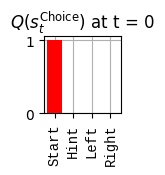

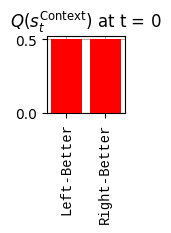

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.11110998083923575)
BEST QIpiI: 0.0


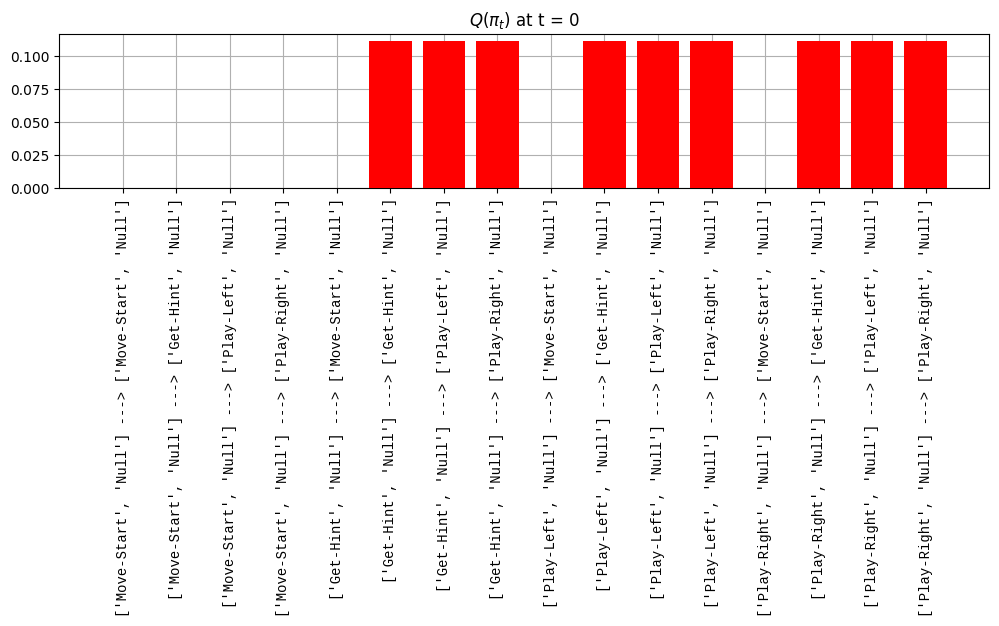

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 0: Play-Left
Context at time 0: Left-Better
Reward at time 0: Null

===================== Time 1: =====================


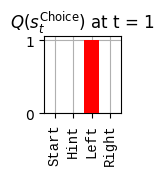

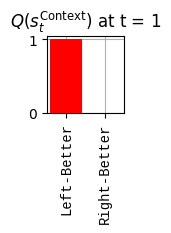

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


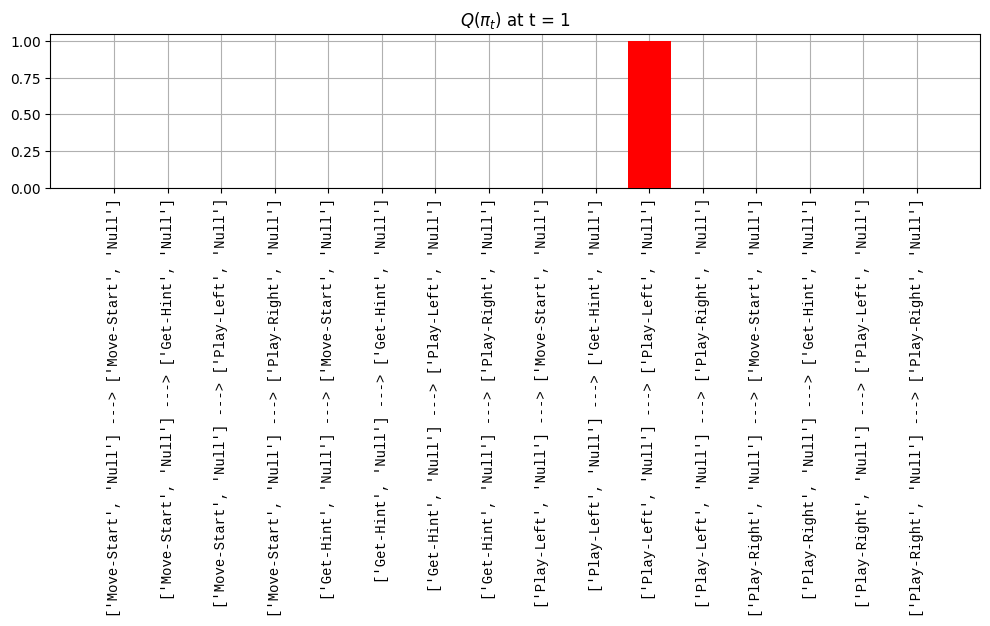

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 1: Play-Left
Context at time 1: Left-Better
Reward at time 1: Null

===================== Time 2: =====================


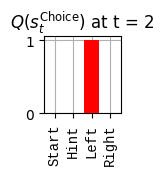

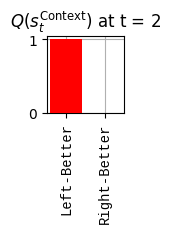

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


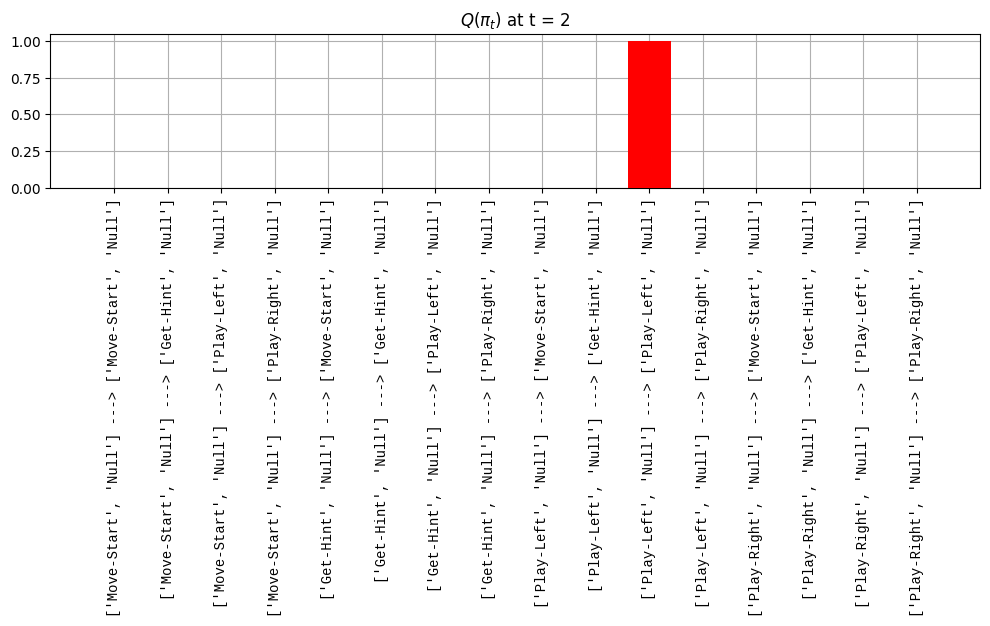

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 2: Play-Left
Context at time 2: Left-Better
Reward at time 2: Null

===================== Time 3: =====================


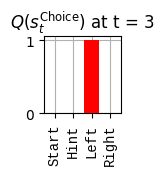

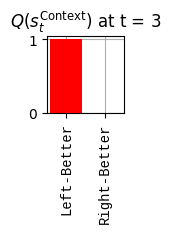

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


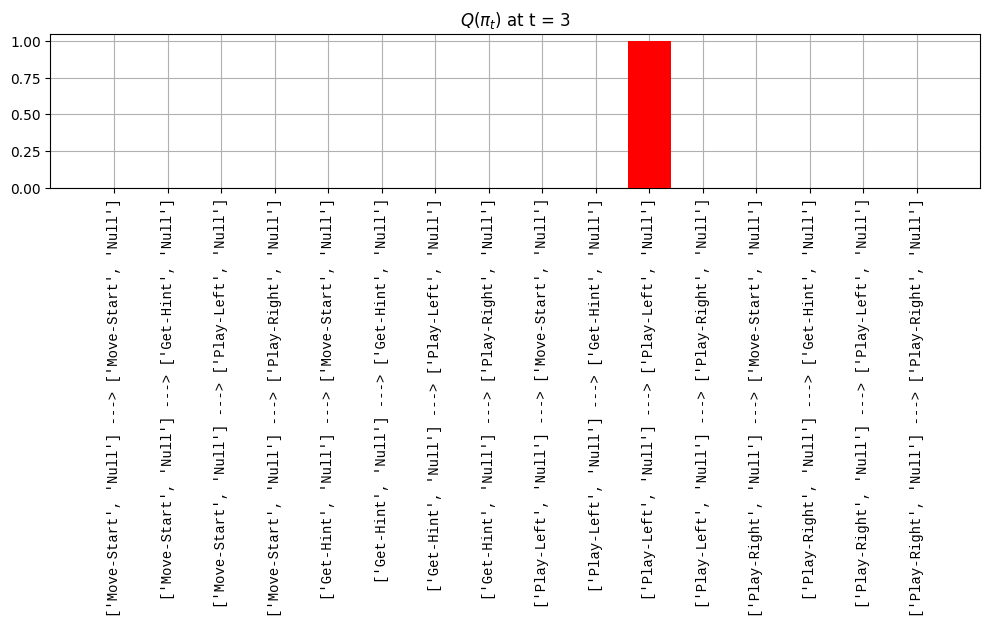

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 3: Play-Left
Context at time 3: Left-Better
Reward at time 3: Null

===================== Time 4: =====================


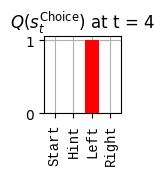

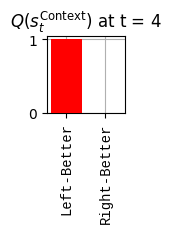

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


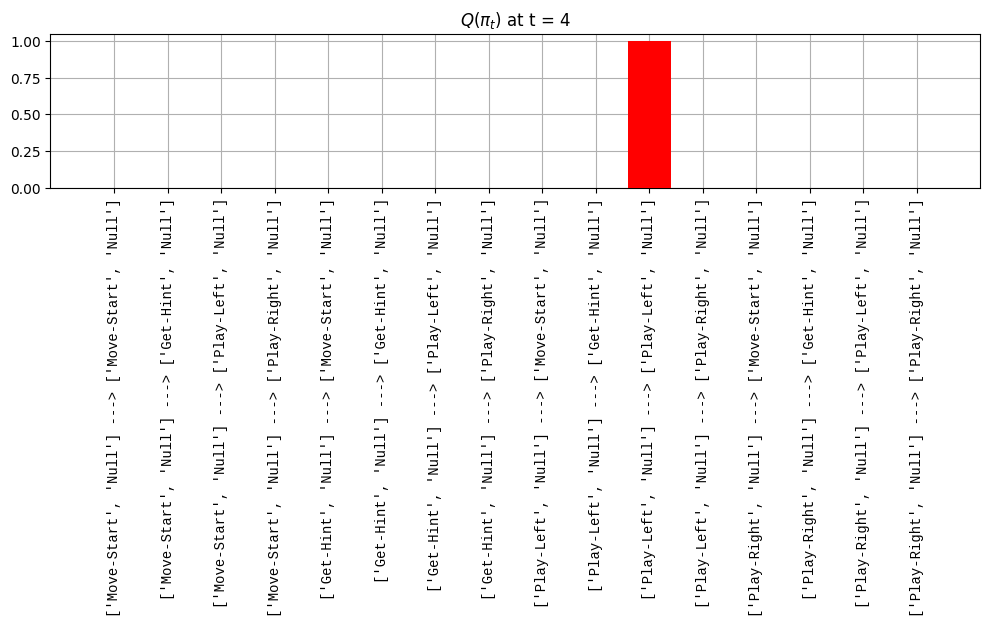

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 4: Play-Left
Context at time 4: Left-Better
Reward at time 4: Null

===================== Time 5: =====================


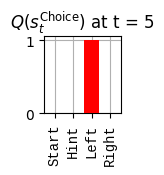

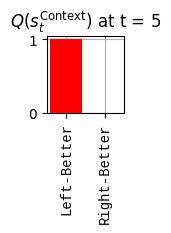

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


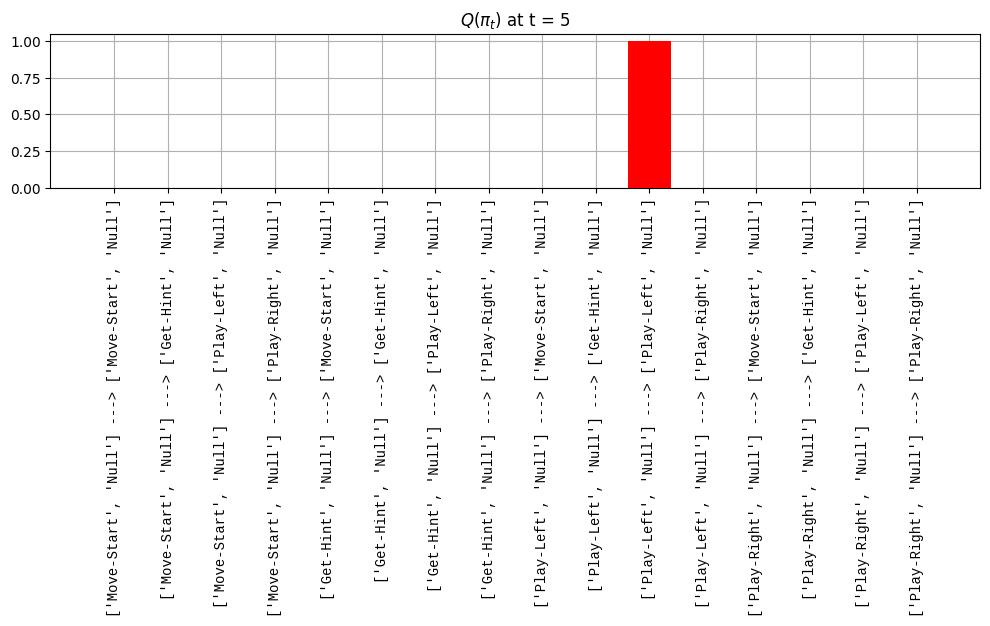

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 5: Play-Left
Context at time 5: Right-Better
Reward at time 5: Null

===================== Time 6: =====================


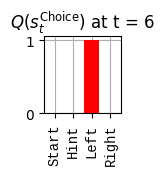

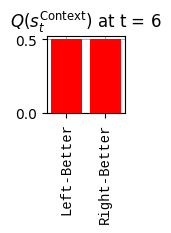

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


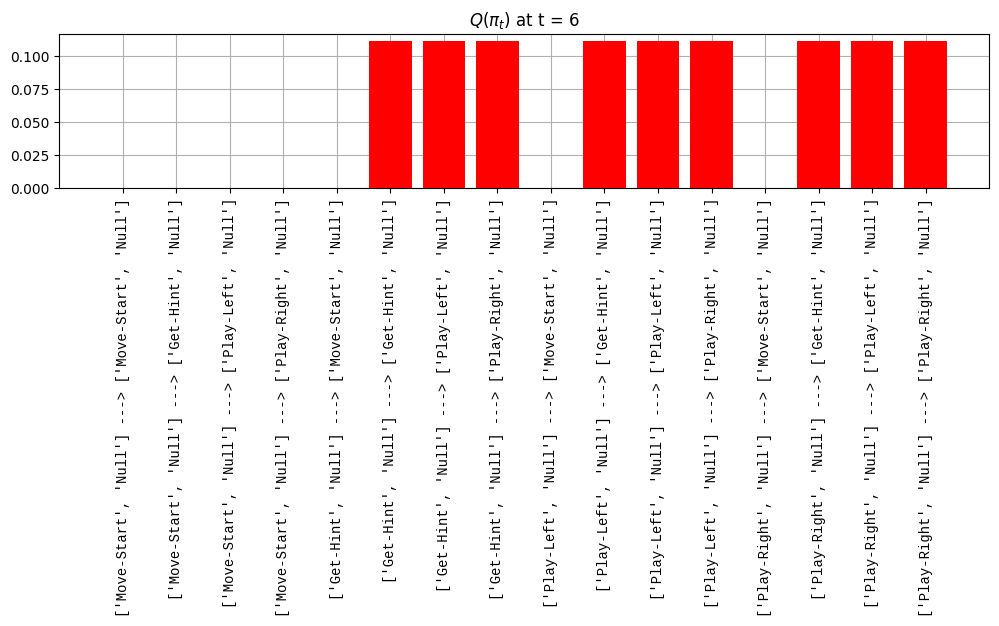

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 6: Play-Left
Context at time 6: Right-Better
Reward at time 6: Null

===================== Time 7: =====================


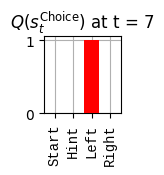

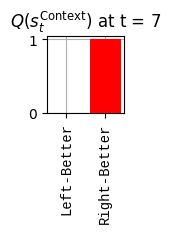

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


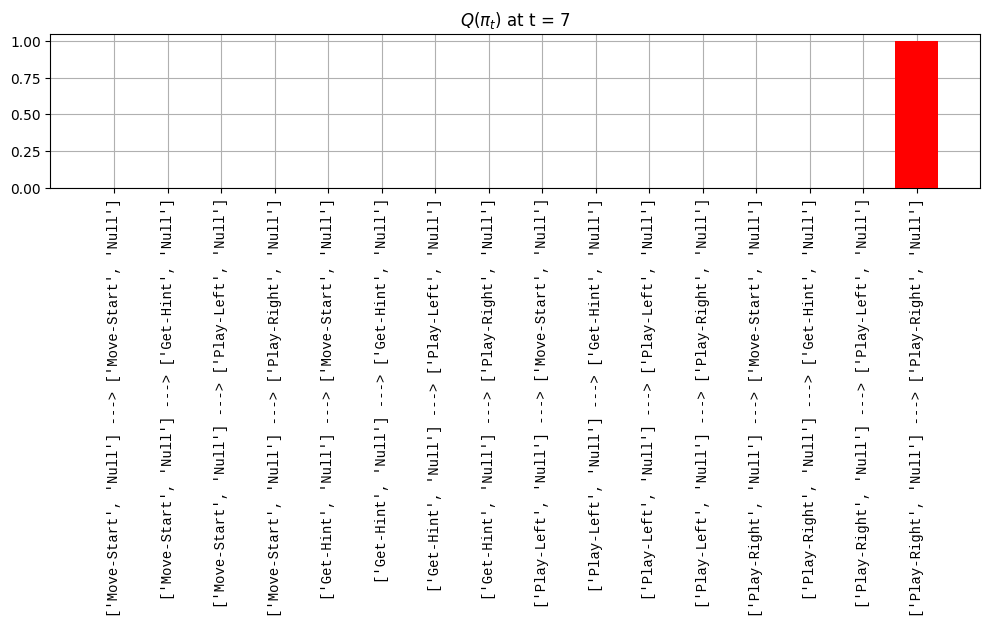

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 7: Play-Right
Context at time 7: Right-Better
Reward at time 7: Null

===================== Time 8: =====================


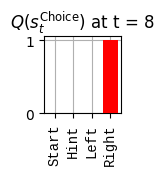

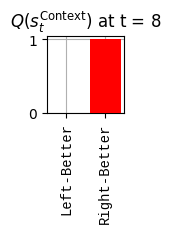

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


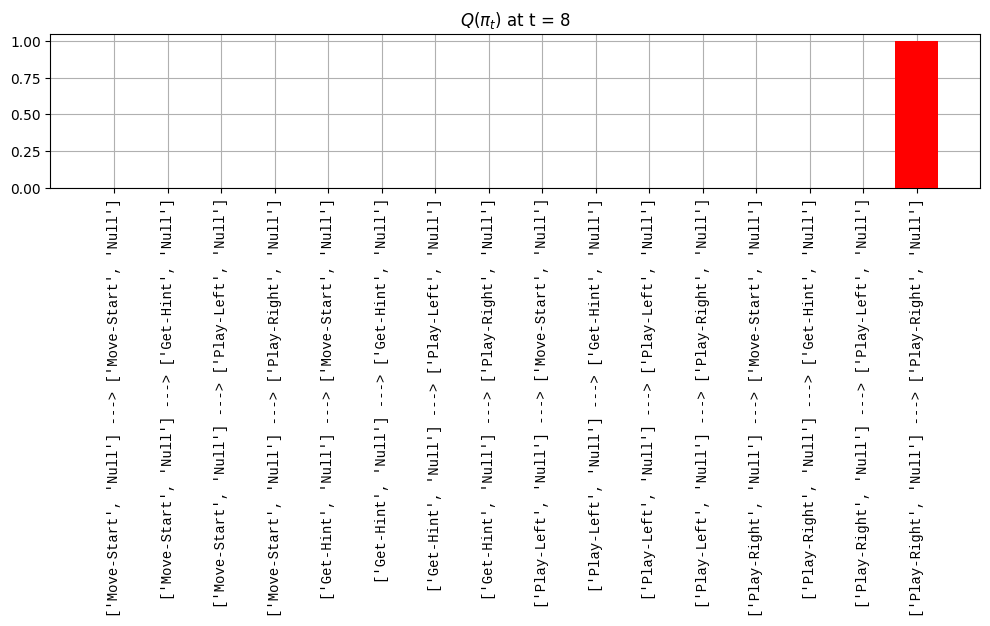

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 8: Play-Right
Context at time 8: Right-Better
Reward at time 8: Null

===================== Time 9: =====================


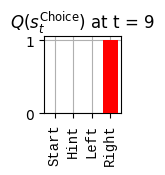

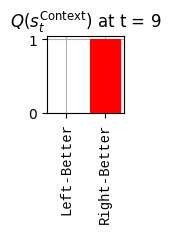

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


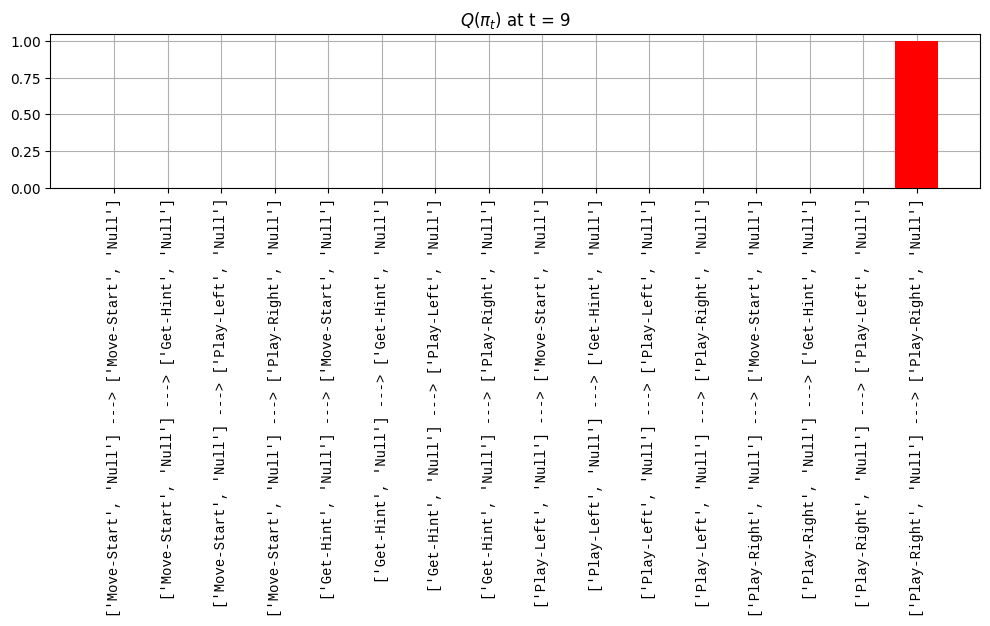

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 9: Play-Right
Context at time 9: Right-Better
Reward at time 9: Null

===================== Time 10: =====================


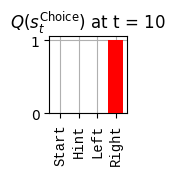

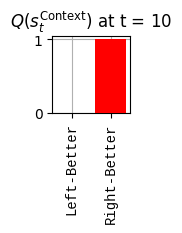

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


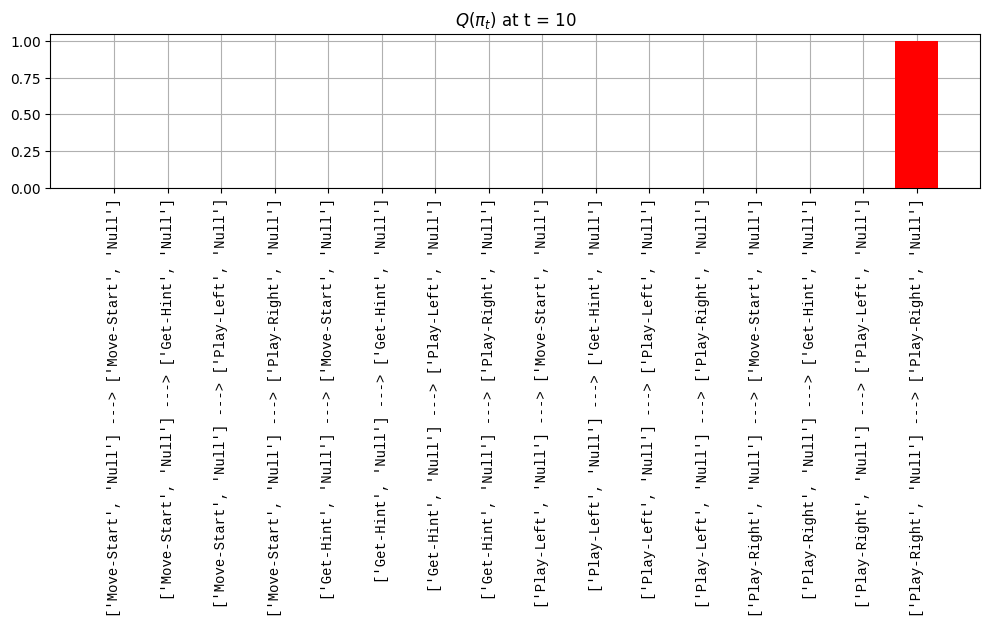

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 10: Play-Right
Context at time 10: Left-Better
Reward at time 10: Null

===================== Time 11: =====================


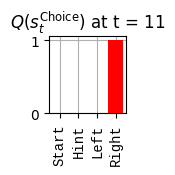

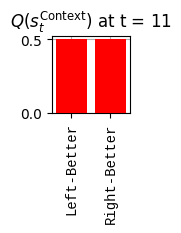

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


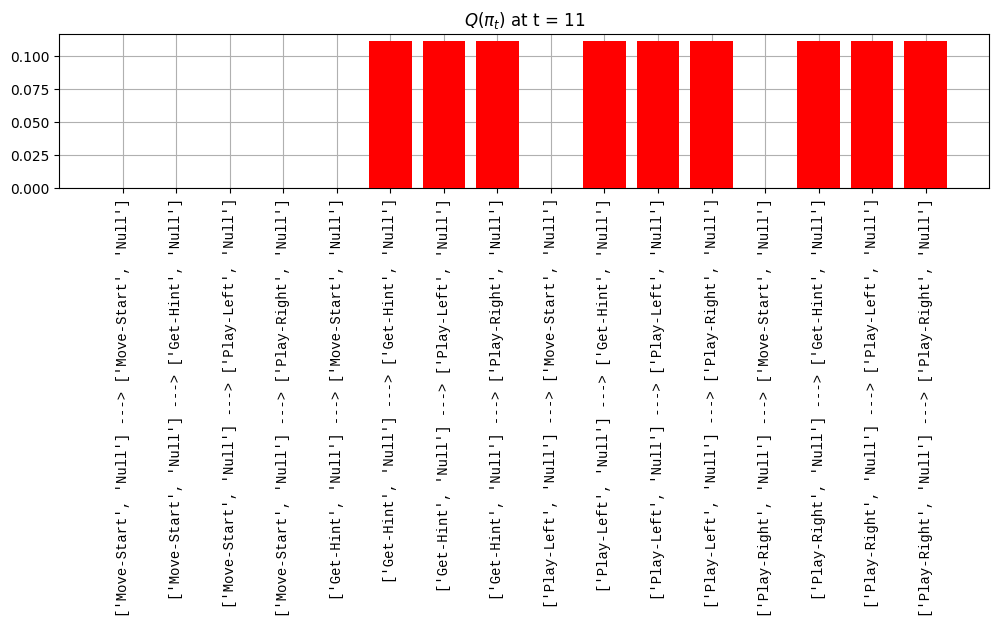

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 11: Play-Right
Context at time 11: Left-Better
Reward at time 11: Null

===================== Time 12: =====================


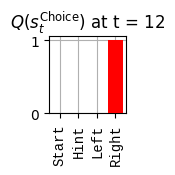

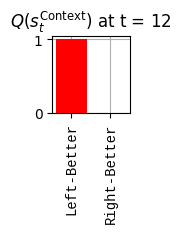

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


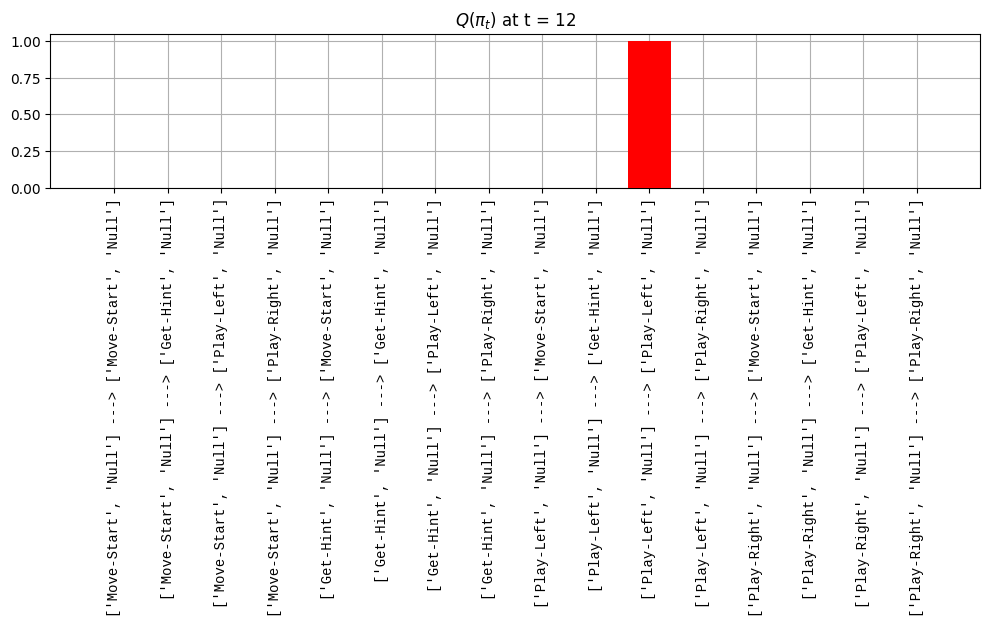

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 12: Play-Left
Context at time 12: Left-Better
Reward at time 12: Null

===================== Time 13: =====================


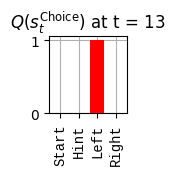

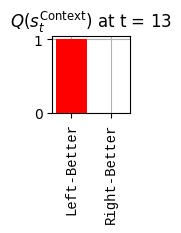

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


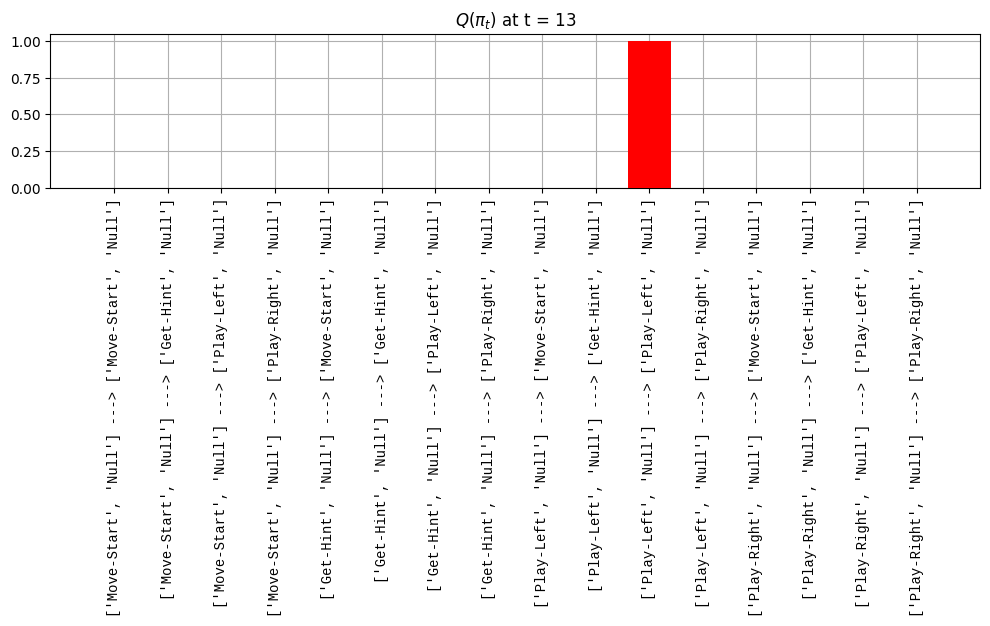

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 13: Play-Left
Context at time 13: Left-Better
Reward at time 13: Null

===================== Time 14: =====================


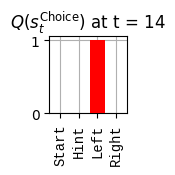

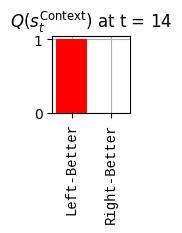

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


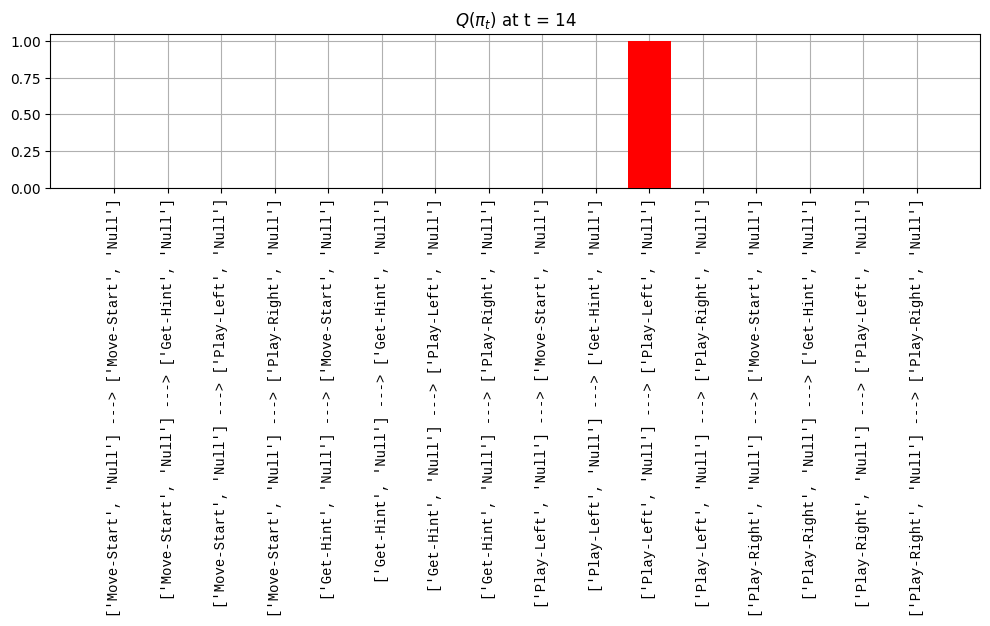

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 14: Play-Left
Context at time 14: Left-Better
Reward at time 14: Null

===================== Time 15: =====================


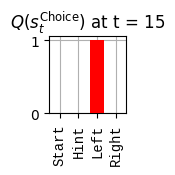

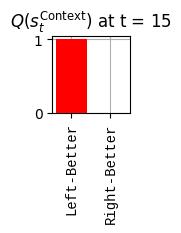

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


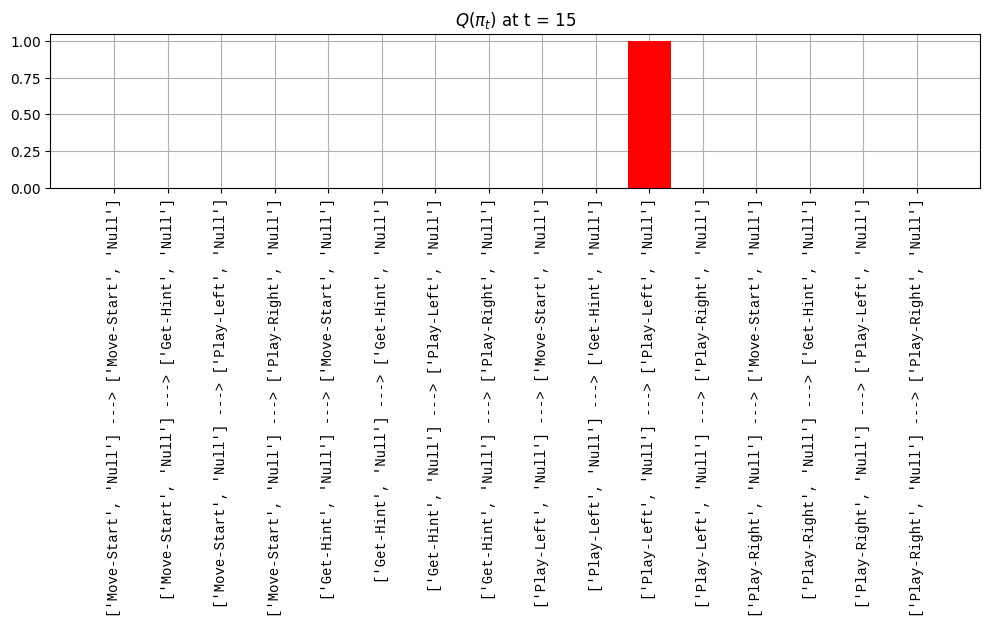

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 15: Play-Left
Context at time 15: Right-Better
Reward at time 15: Null

===================== Time 16: =====================


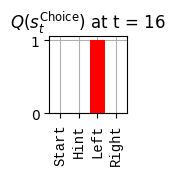

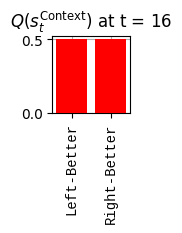

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


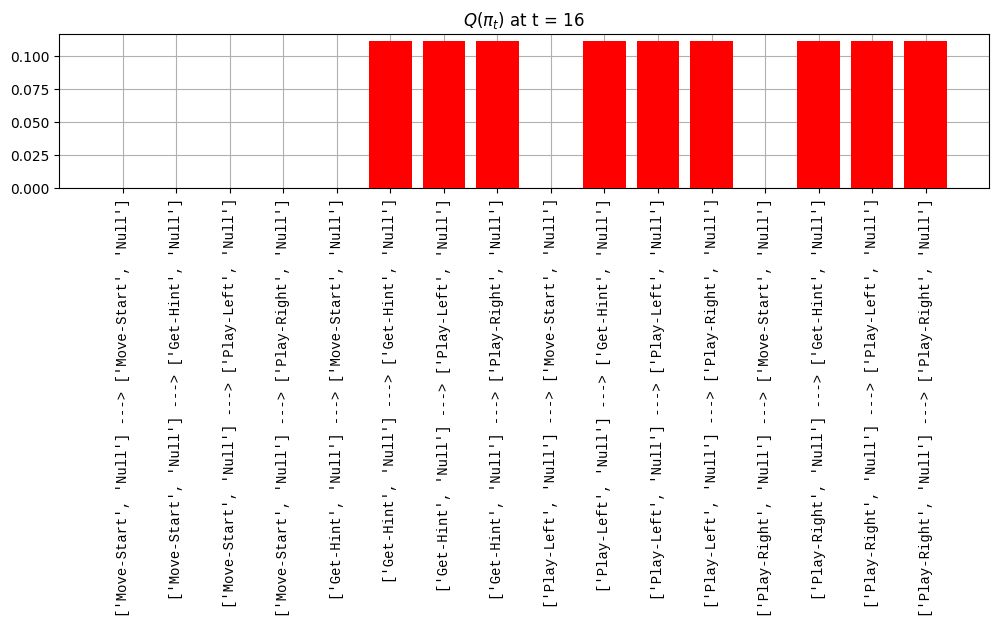

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 16: Play-Left
Context at time 16: Right-Better
Reward at time 16: Null

===================== Time 17: =====================


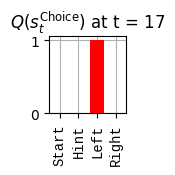

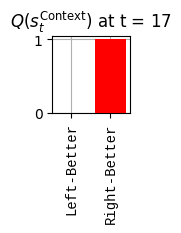

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


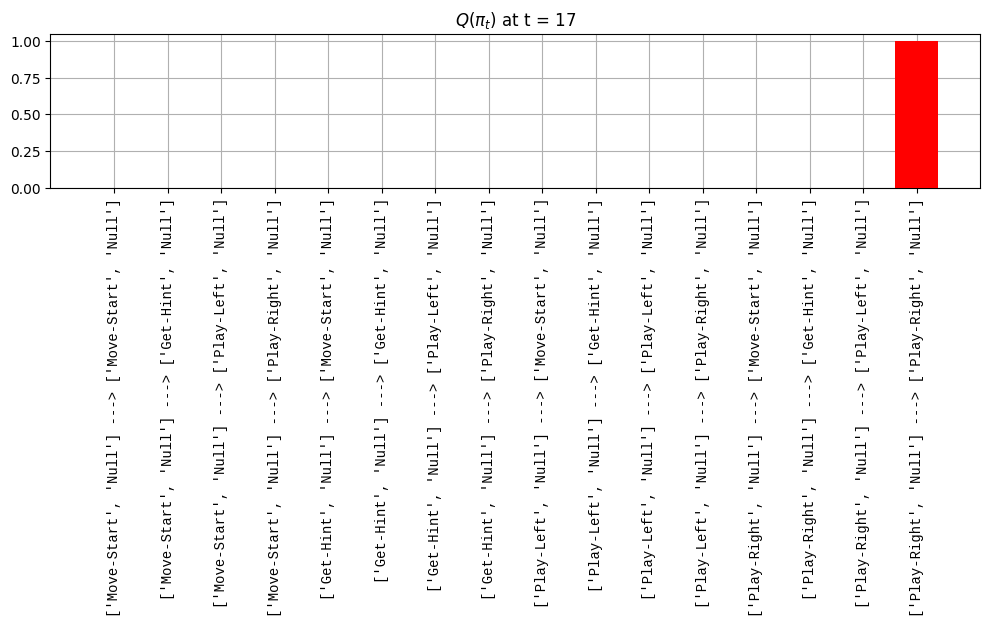

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 17: Play-Right
Context at time 17: Right-Better
Reward at time 17: Null

===================== Time 18: =====================


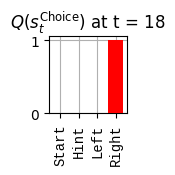

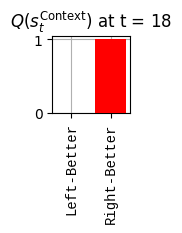

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


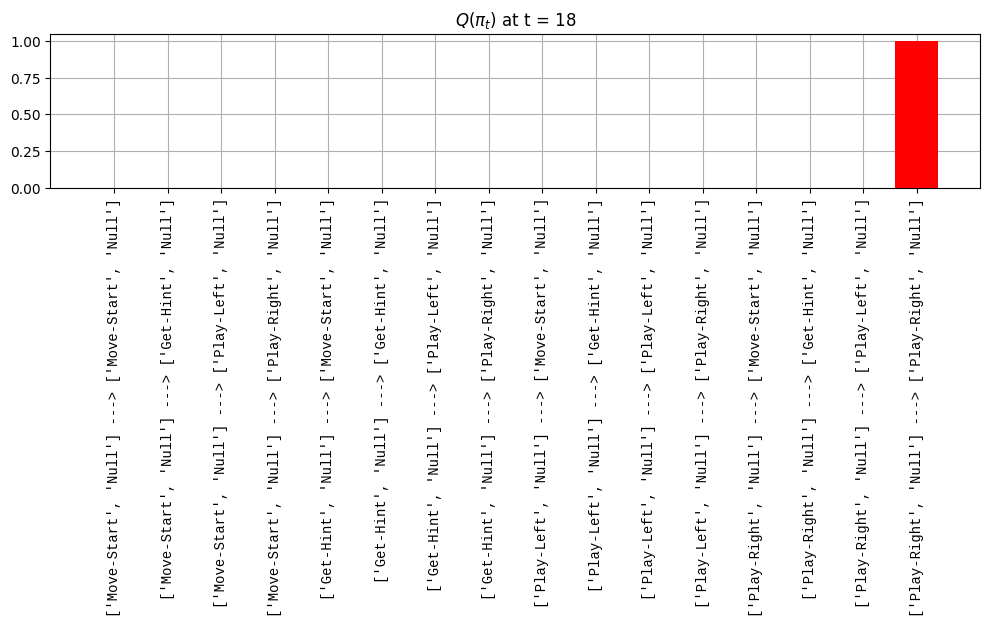

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 18: Play-Right
Context at time 18: Right-Better
Reward at time 18: Null

===================== Time 19: =====================


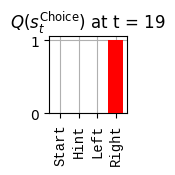

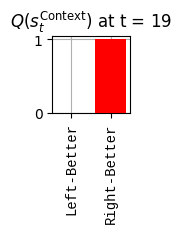

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


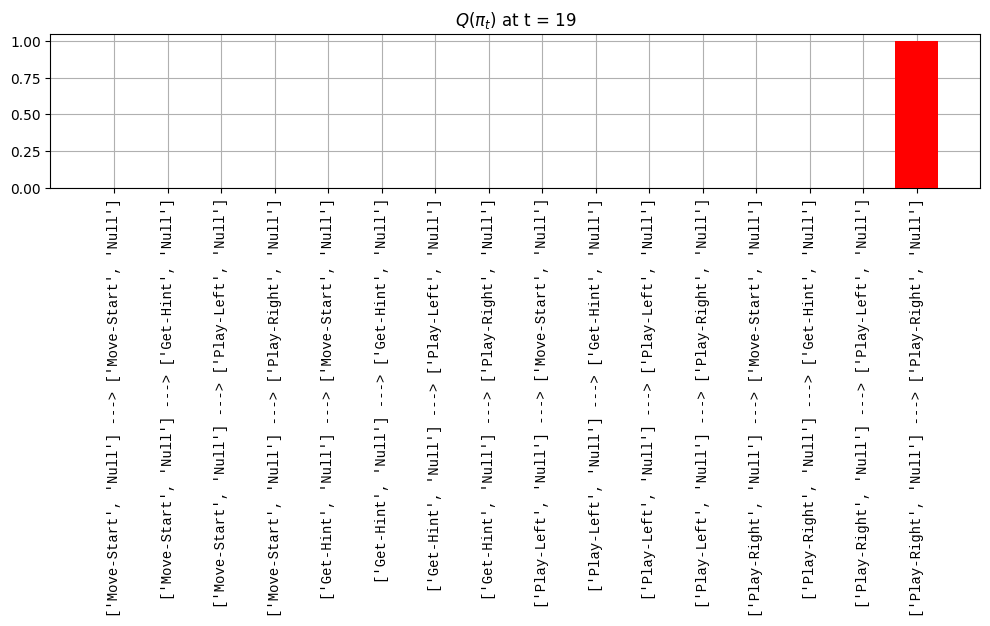

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 19: Play-Right
Context at time 19: Right-Better
Reward at time 19: Null

===================== Time 20: =====================


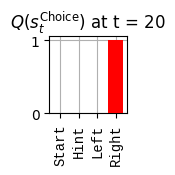

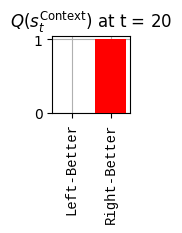

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


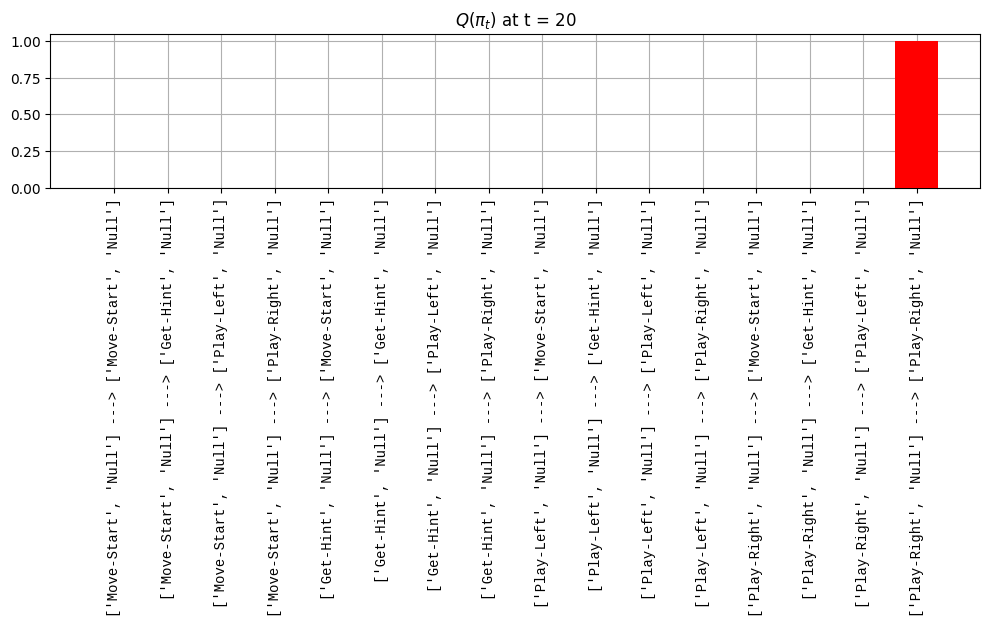

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 20: Play-Right
Context at time 20: Left-Better
Reward at time 20: Null

===================== Time 21: =====================


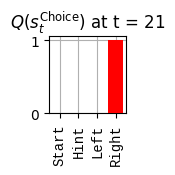

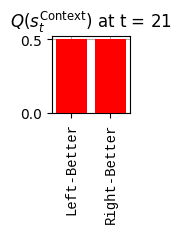

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


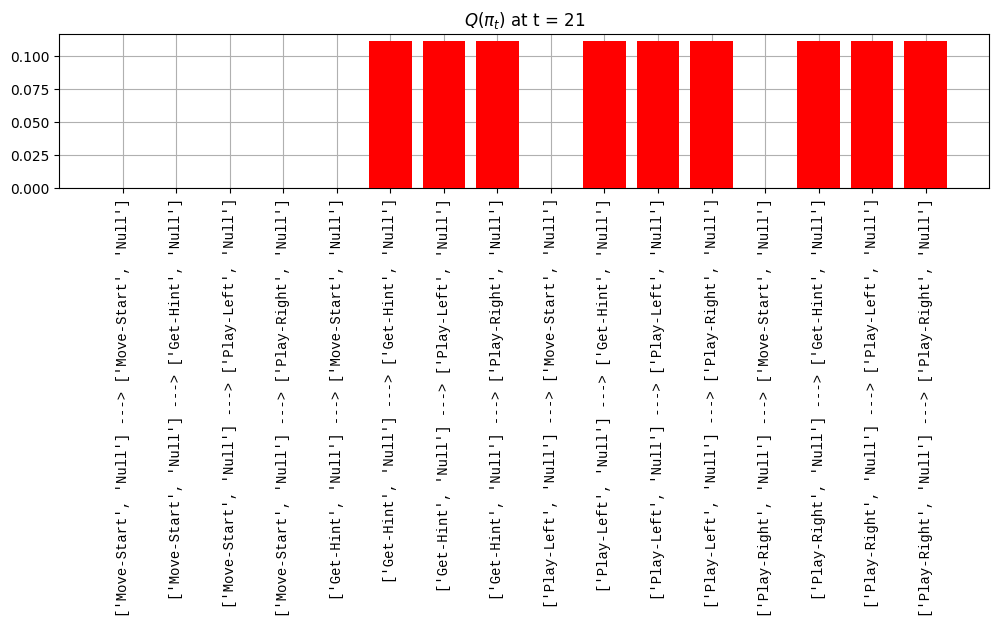

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 21: Play-Right
Context at time 21: Left-Better
Reward at time 21: Null

===================== Time 22: =====================


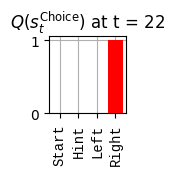

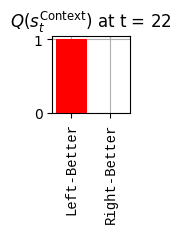

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


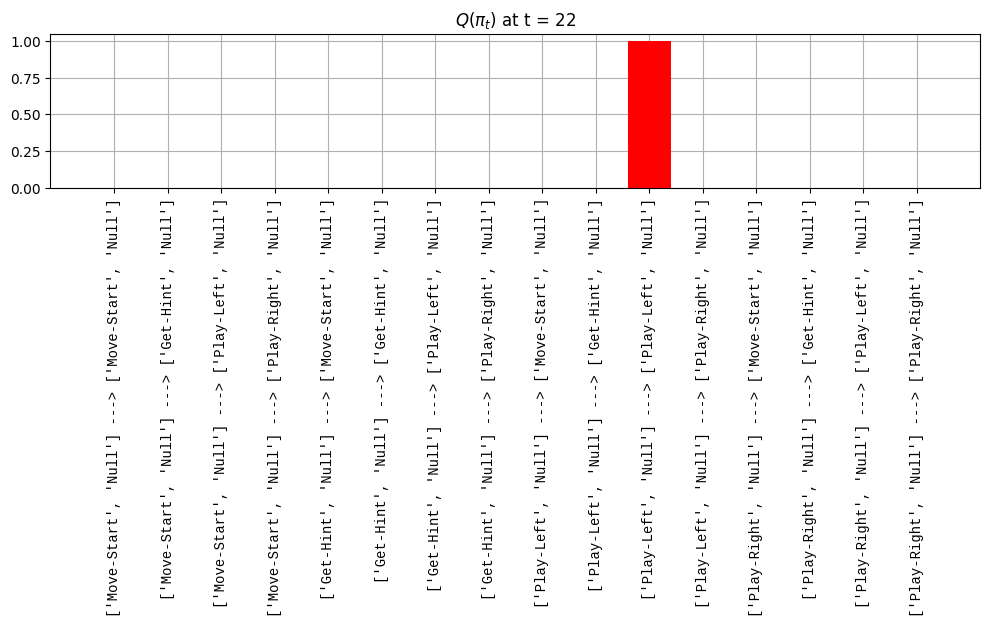

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 22: Play-Left
Context at time 22: Left-Better
Reward at time 22: Null

===================== Time 23: =====================


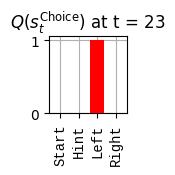

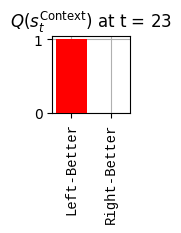

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


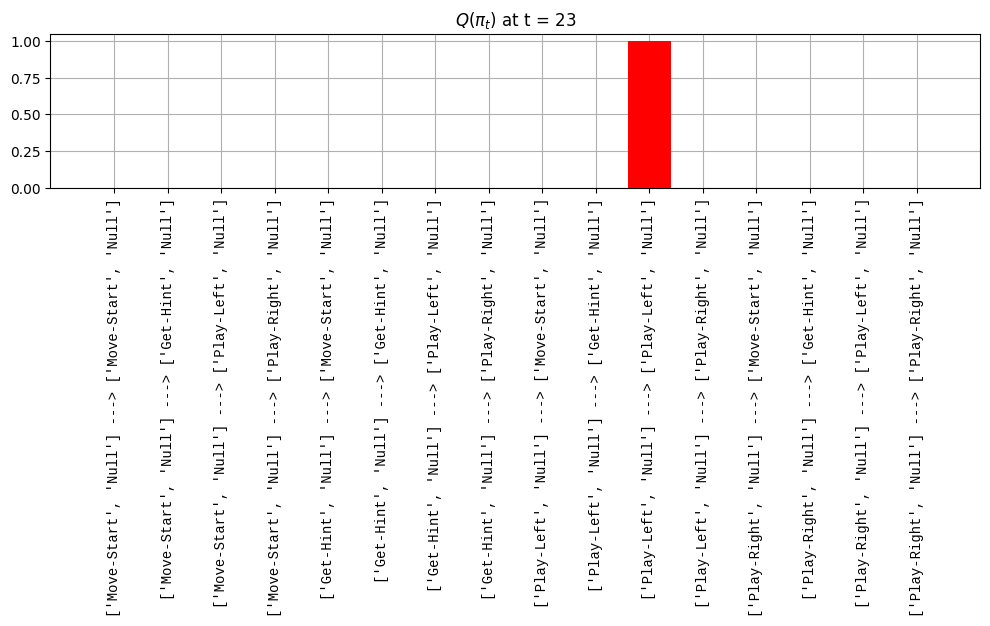

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 23: Play-Left
Context at time 23: Left-Better
Reward at time 23: Null

===================== Time 24: =====================


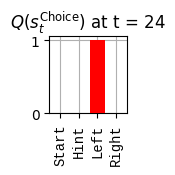

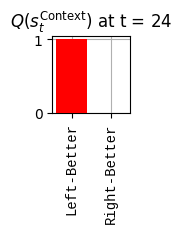

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


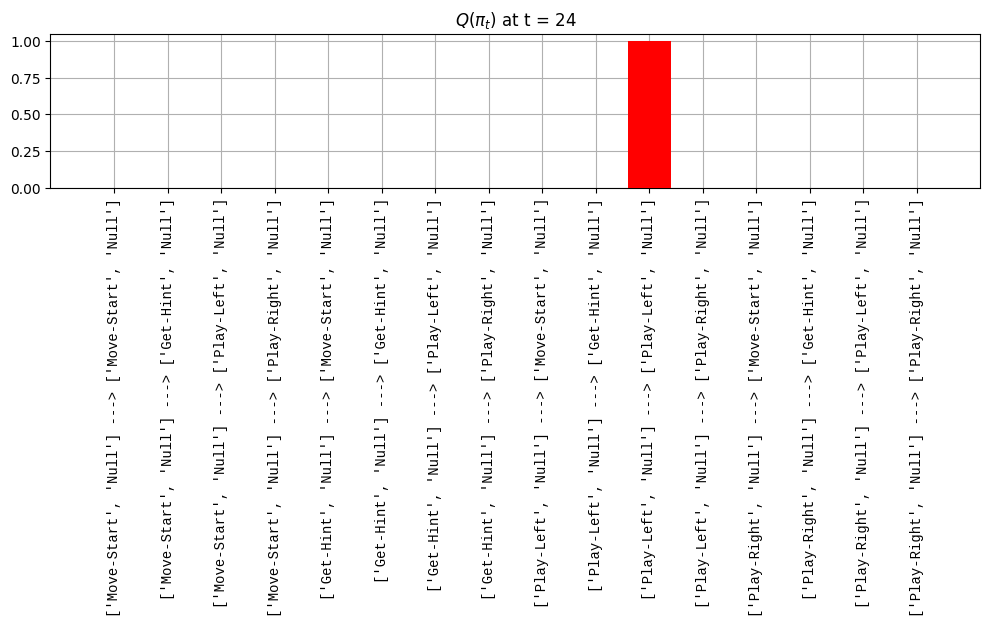

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 24: Play-Left
Context at time 24: Left-Better
Reward at time 24: Null

===================== Time 25: =====================


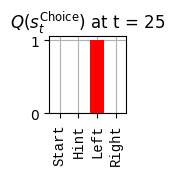

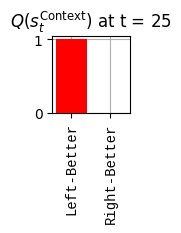

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


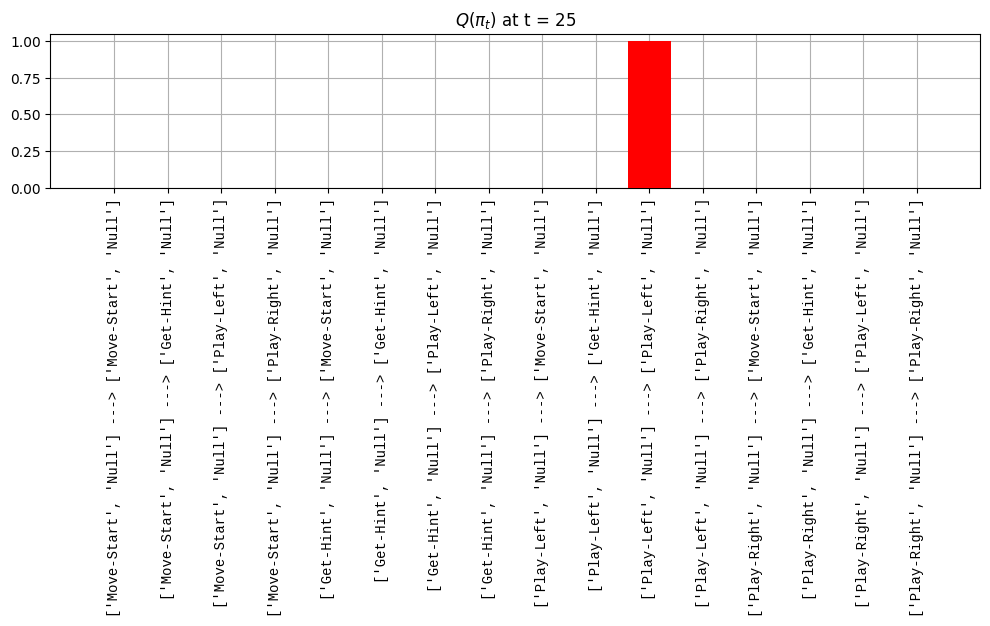

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 25: Play-Left
Context at time 25: Right-Better
Reward at time 25: Null

===================== Time 26: =====================


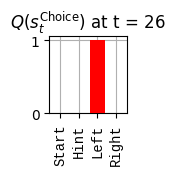

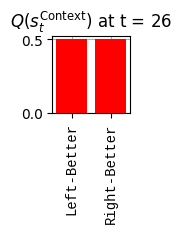

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


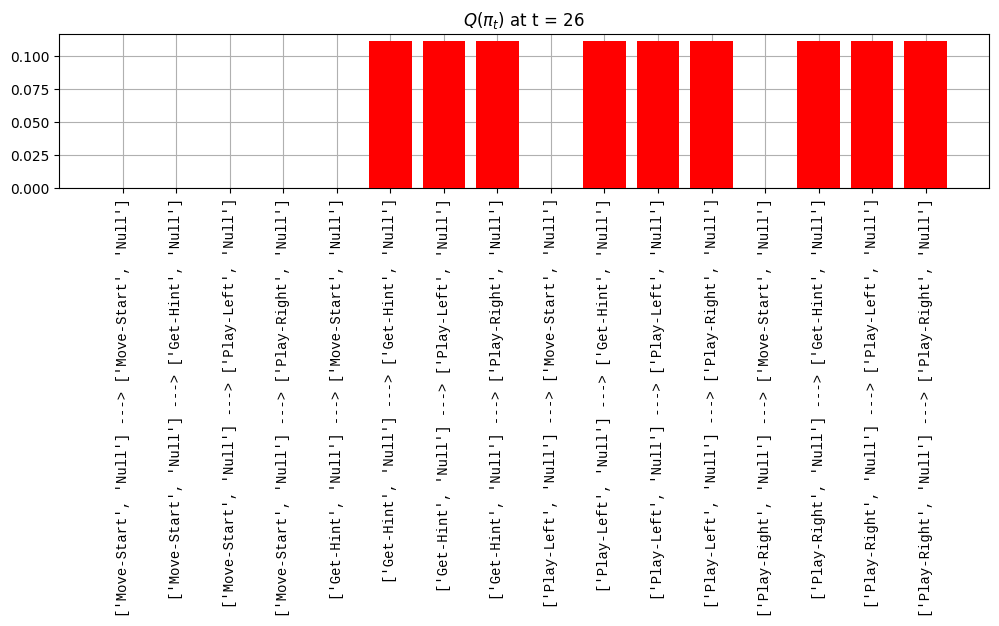

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 26: Play-Left
Context at time 26: Right-Better
Reward at time 26: Null

===================== Time 27: =====================


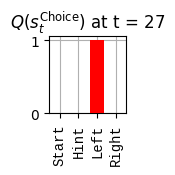

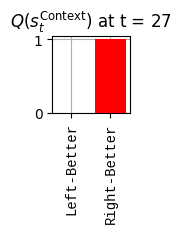

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


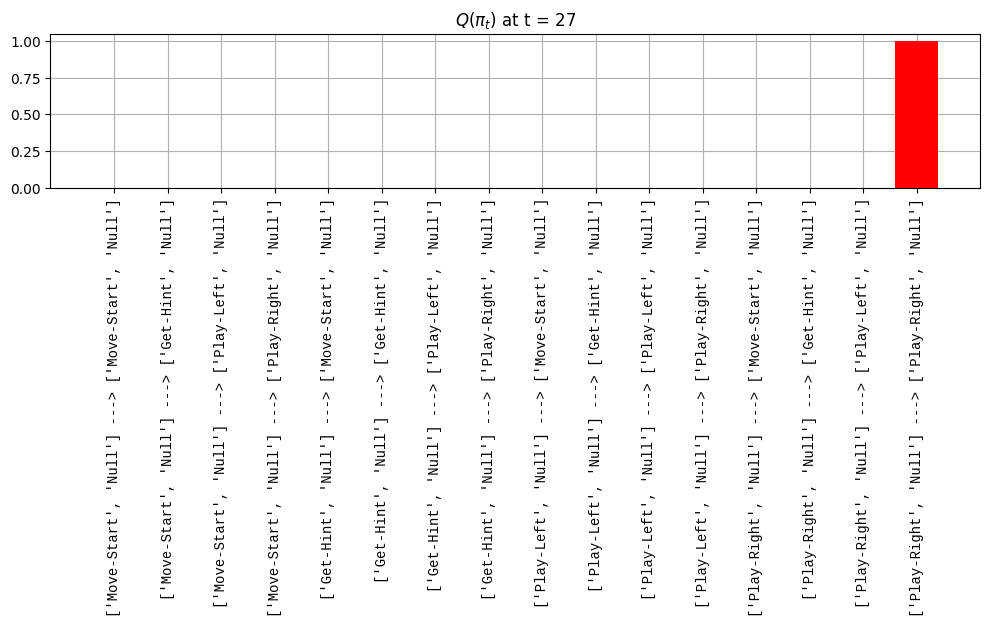

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 27: Play-Right
Context at time 27: Right-Better
Reward at time 27: Null

===================== Time 28: =====================


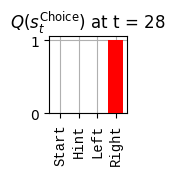

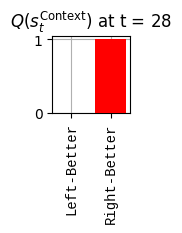

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


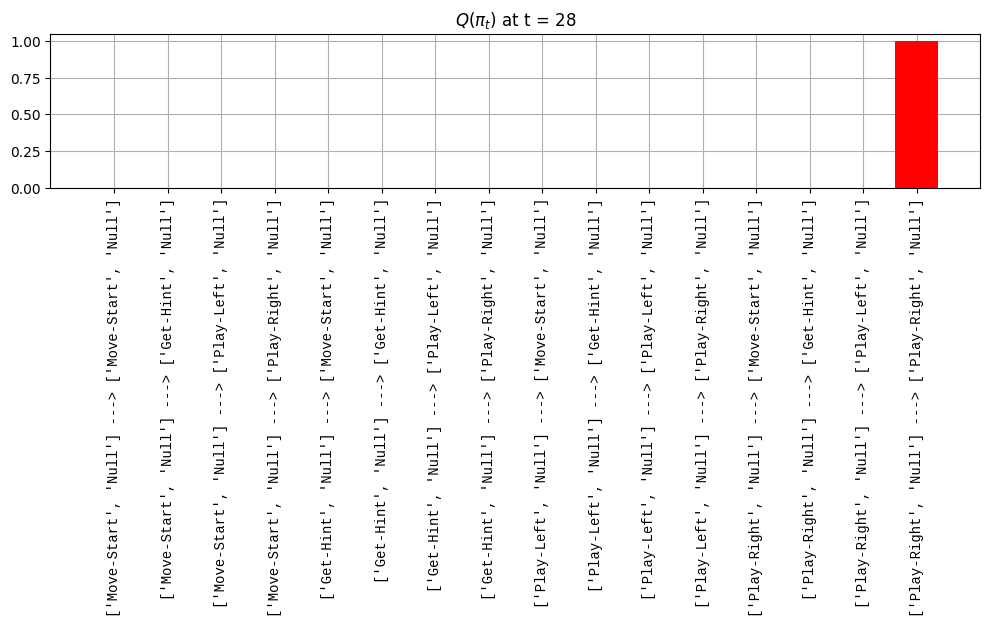

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 28: Play-Right
Context at time 28: Right-Better
Reward at time 28: Null

===================== Time 29: =====================


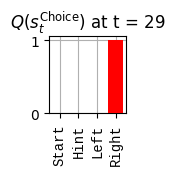

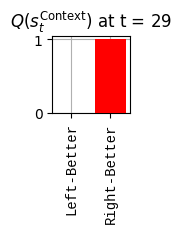

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


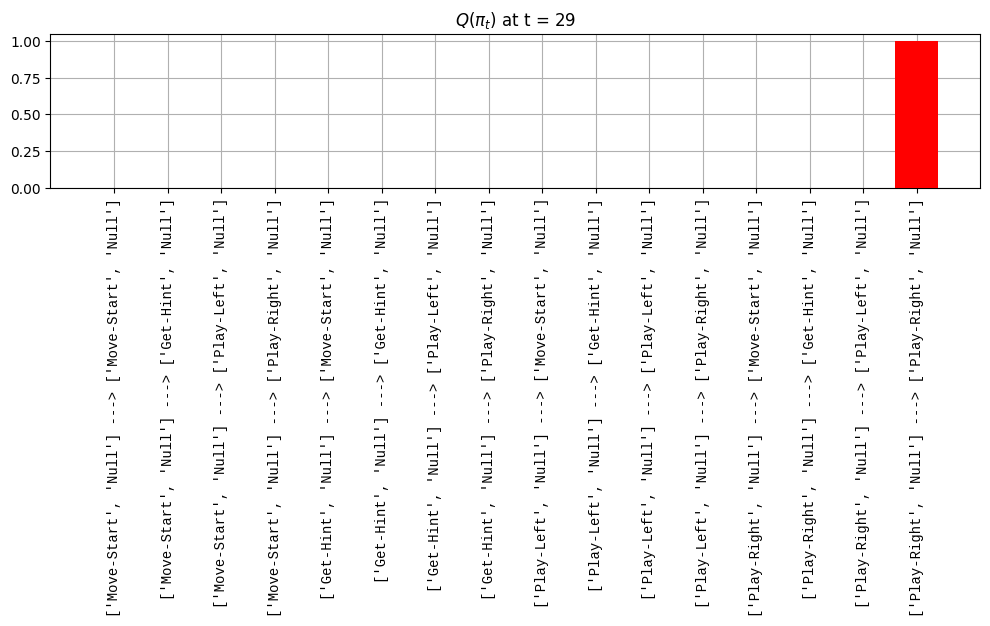

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 29: Play-Right
Context at time 29: Right-Better
Reward at time 29: Null

===================== Time 30: =====================


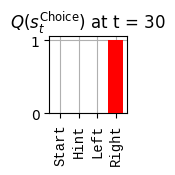

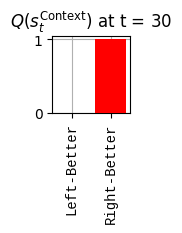

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


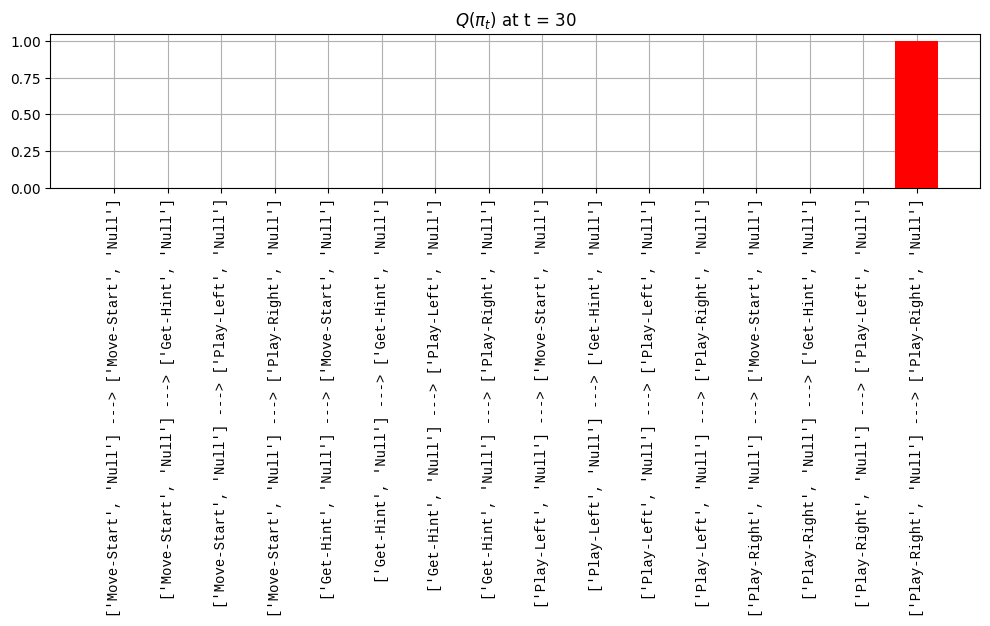

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 30: Play-Right
Context at time 30: Left-Better
Reward at time 30: Null

===================== Time 31: =====================


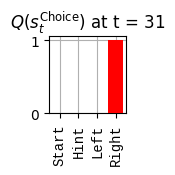

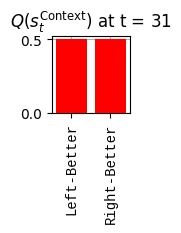

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


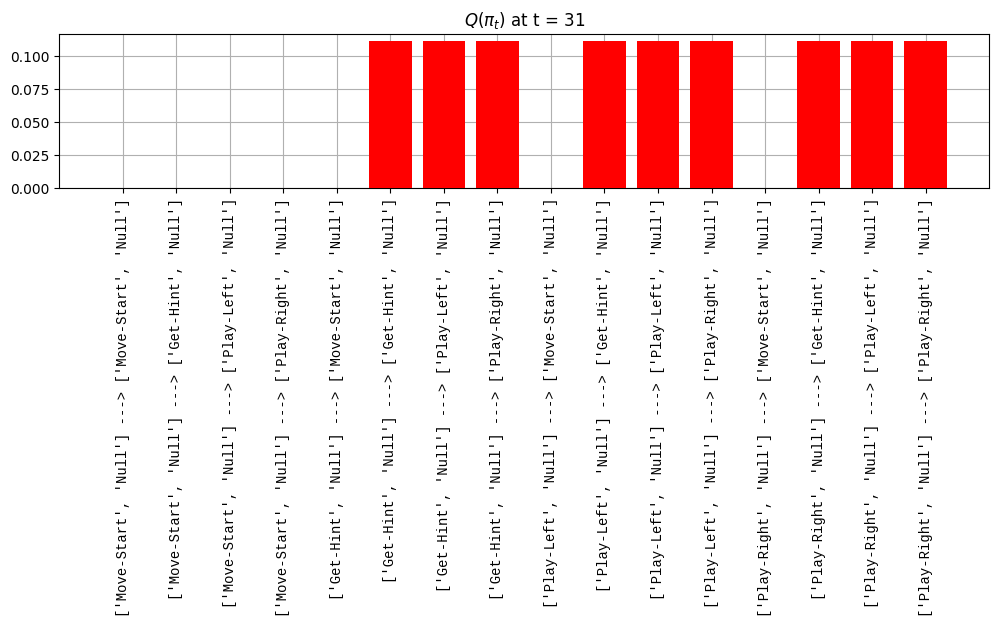

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 31: Play-Right
Context at time 31: Left-Better
Reward at time 31: Null

===================== Time 32: =====================


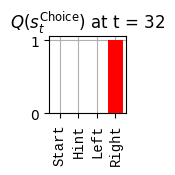

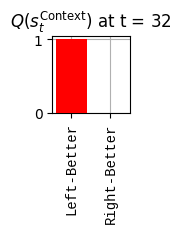

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


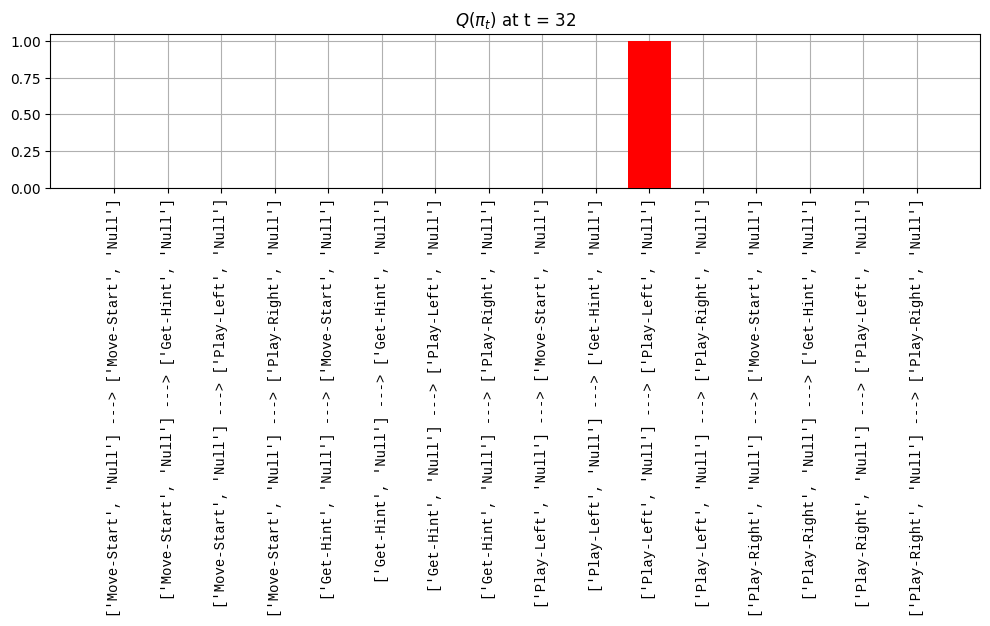

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 32: Play-Left
Context at time 32: Left-Better
Reward at time 32: Null

===================== Time 33: =====================


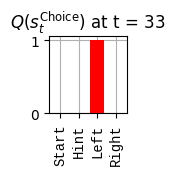

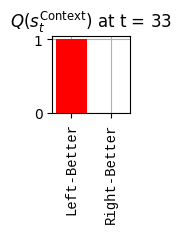

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


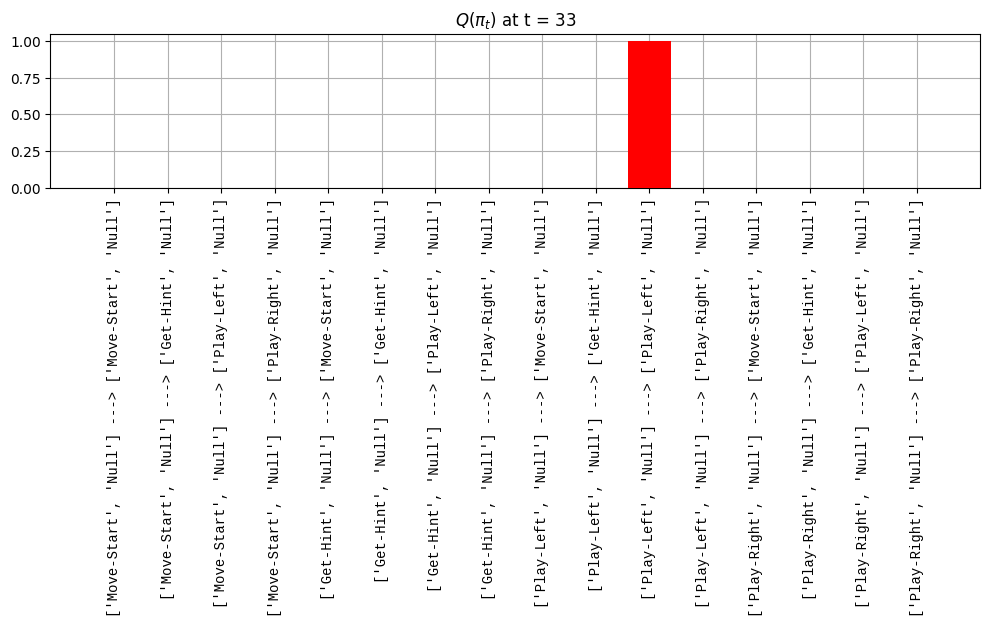

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 33: Play-Left
Context at time 33: Left-Better
Reward at time 33: Null

===================== Time 34: =====================


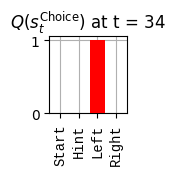

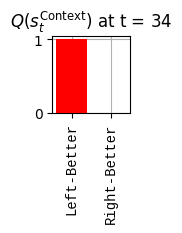

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


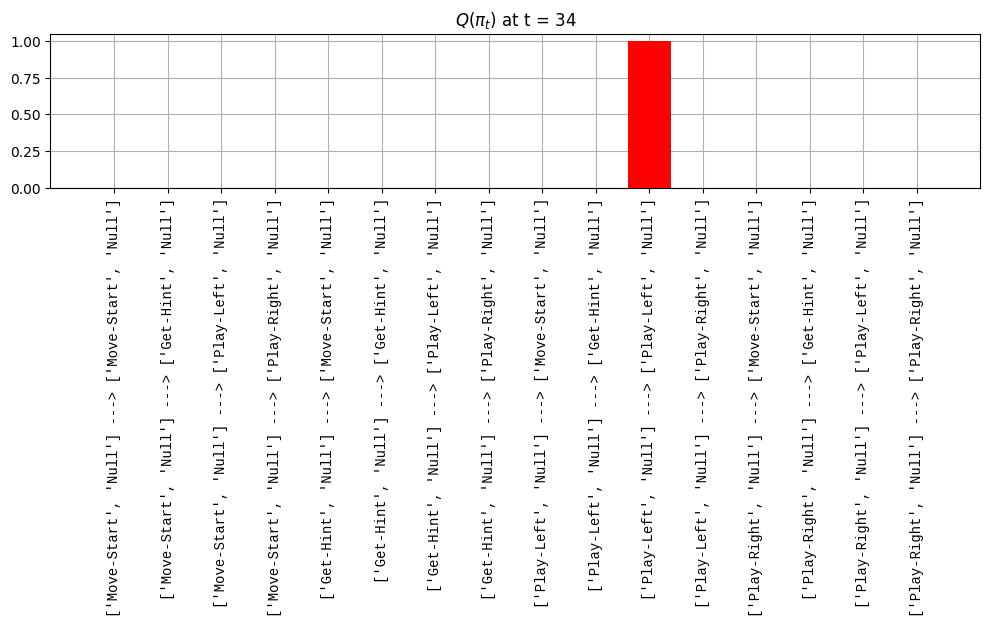

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 34: Play-Left
Context at time 34: Left-Better
Reward at time 34: Null

===================== Time 35: =====================


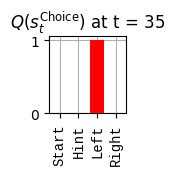

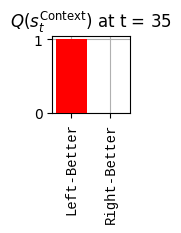

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


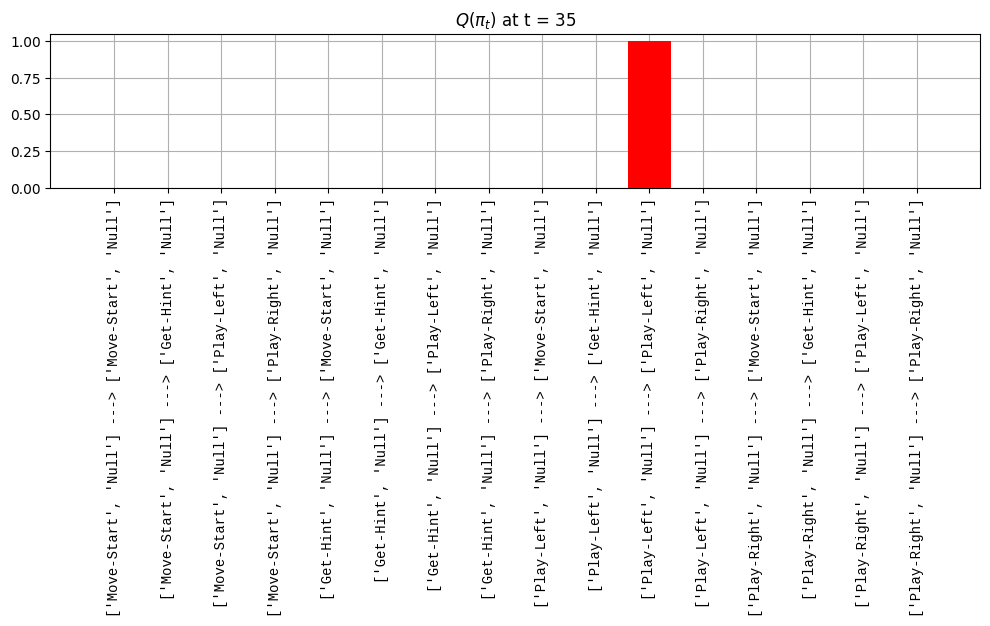

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 35: Play-Left
Context at time 35: Right-Better
Reward at time 35: Null

===================== Time 36: =====================


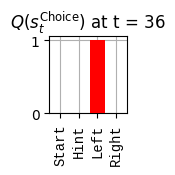

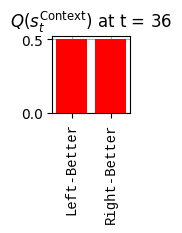

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


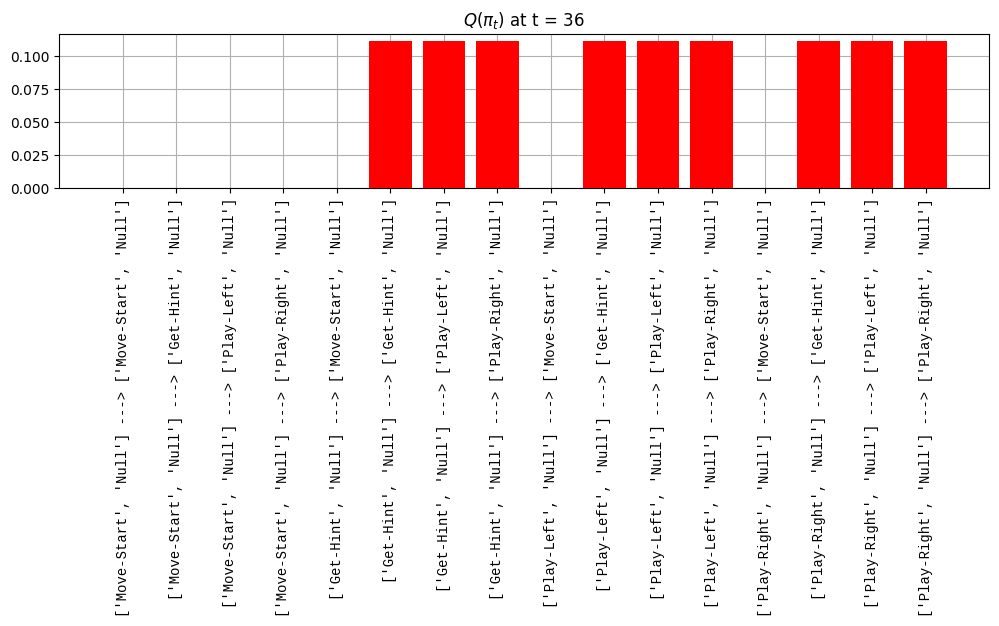

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 36: Play-Left
Context at time 36: Right-Better
Reward at time 36: Null

===================== Time 37: =====================


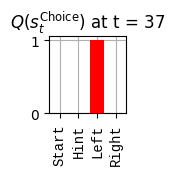

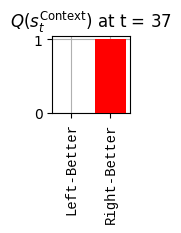

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


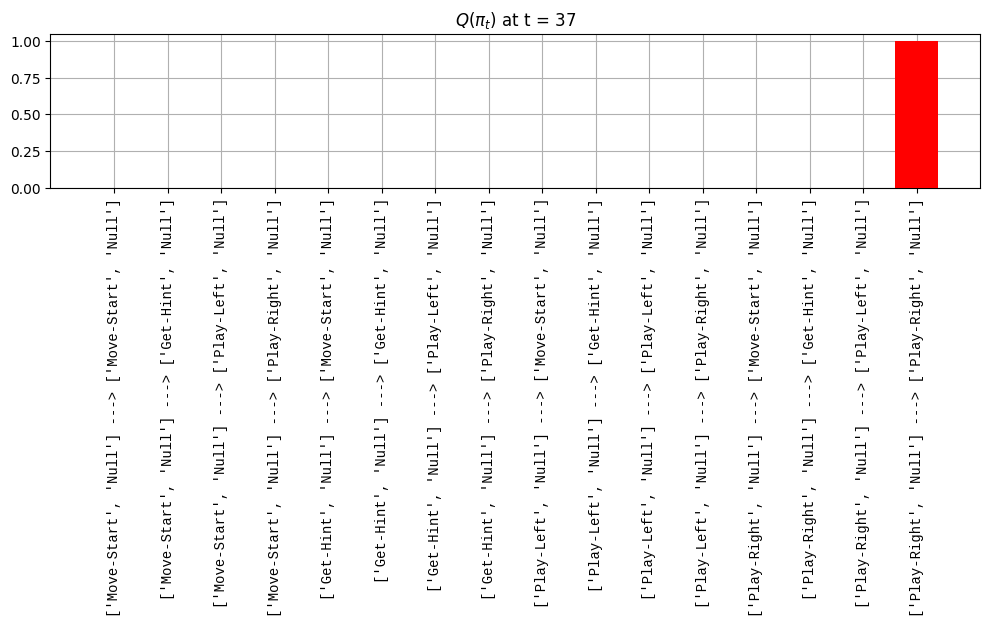

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 37: Play-Right
Context at time 37: Right-Better
Reward at time 37: Null

===================== Time 38: =====================


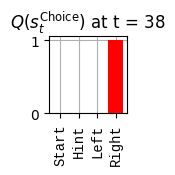

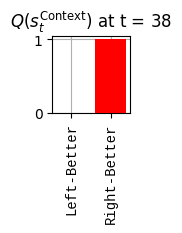

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


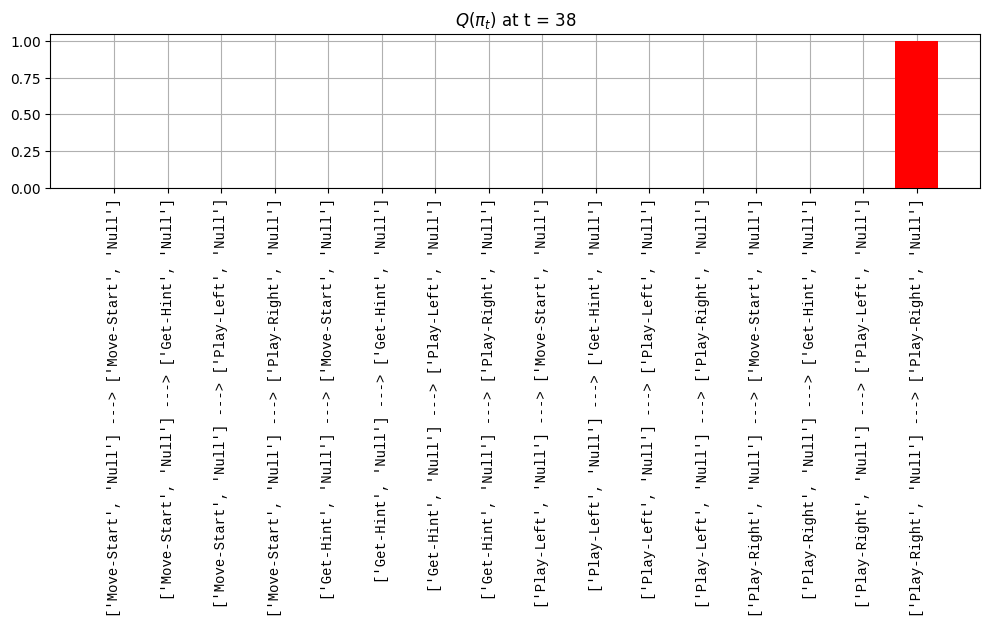

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 38: Play-Right
Context at time 38: Right-Better
Reward at time 38: Null

===================== Time 39: =====================


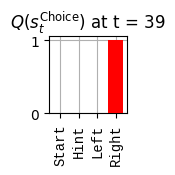

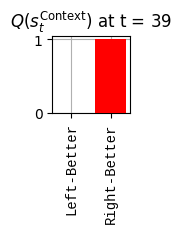

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


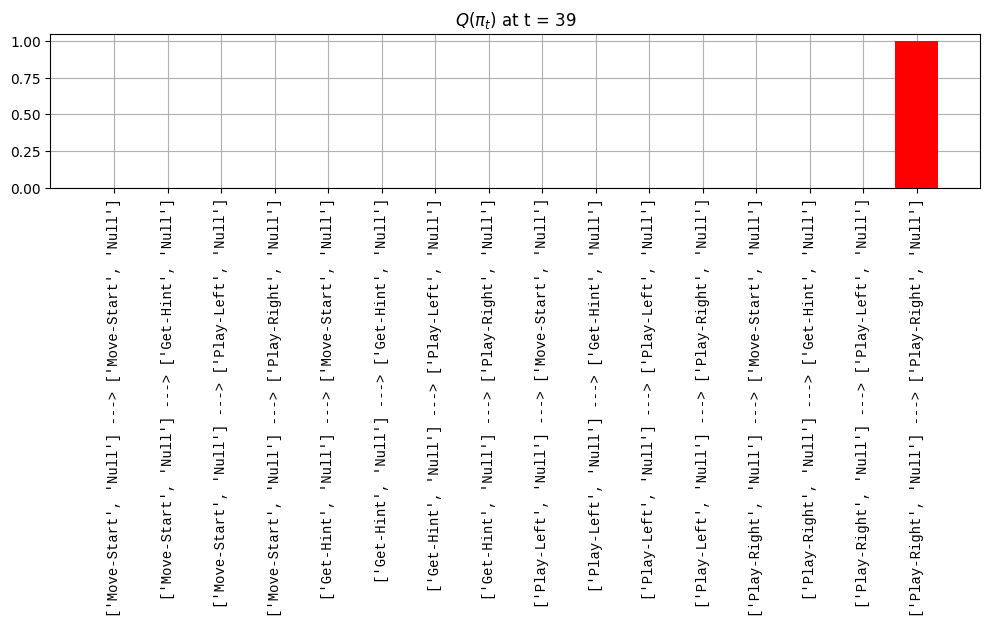

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 39: Play-Right
Context at time 39: Right-Better
Reward at time 39: Null

===================== Time 40: =====================


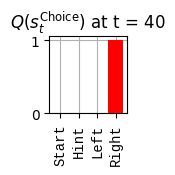

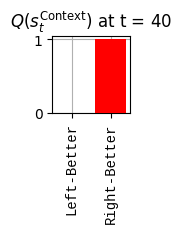

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


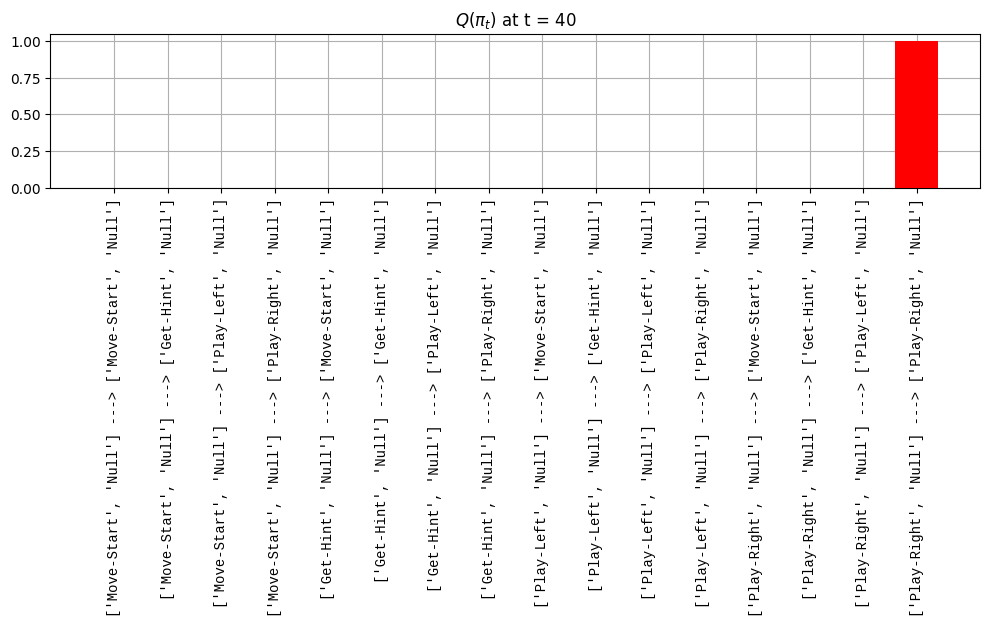

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 40: Play-Right
Context at time 40: Left-Better
Reward at time 40: Null

===================== Time 41: =====================


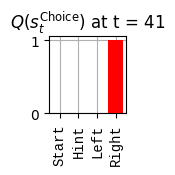

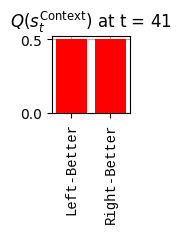

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


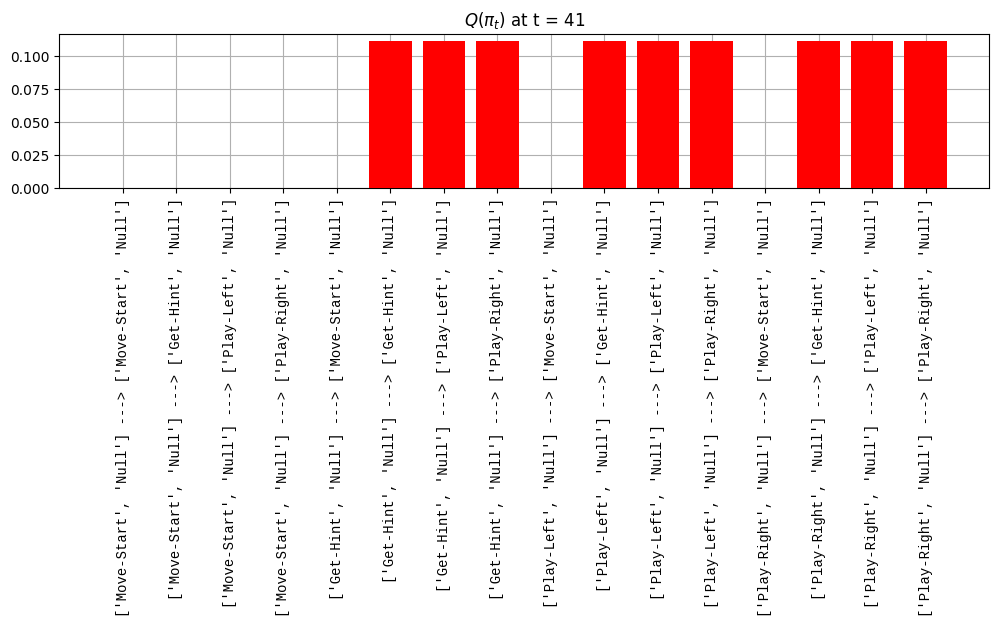

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 41: Play-Right
Context at time 41: Left-Better
Reward at time 41: Null

===================== Time 42: =====================


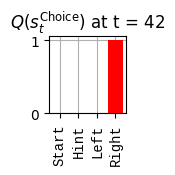

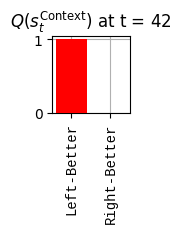

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


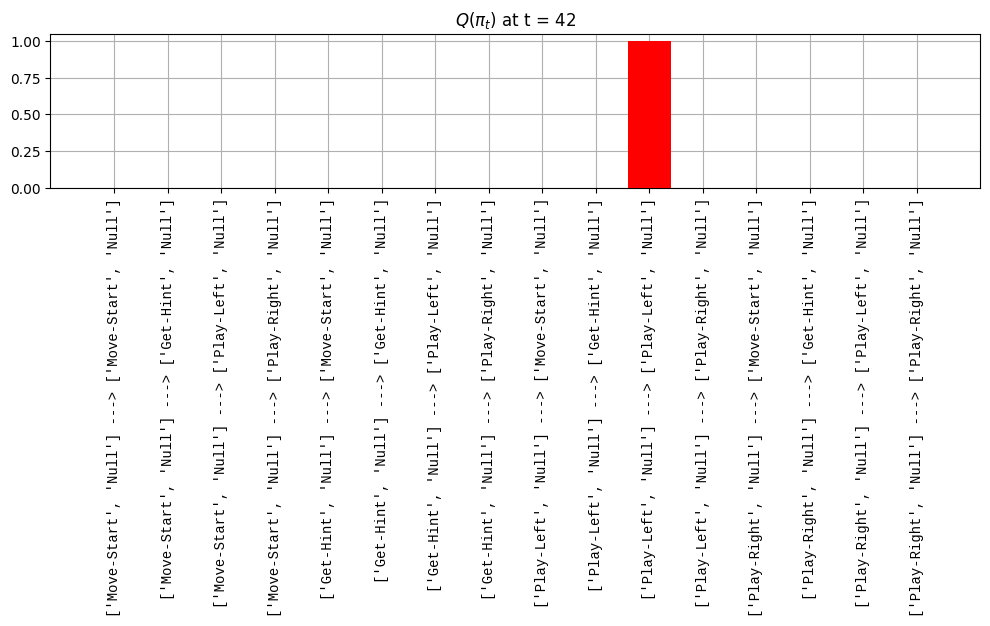

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 42: Play-Left
Context at time 42: Left-Better
Reward at time 42: Null

===================== Time 43: =====================


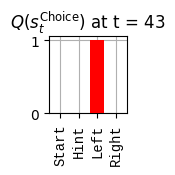

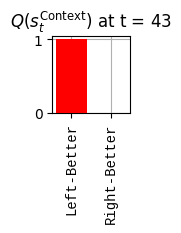

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


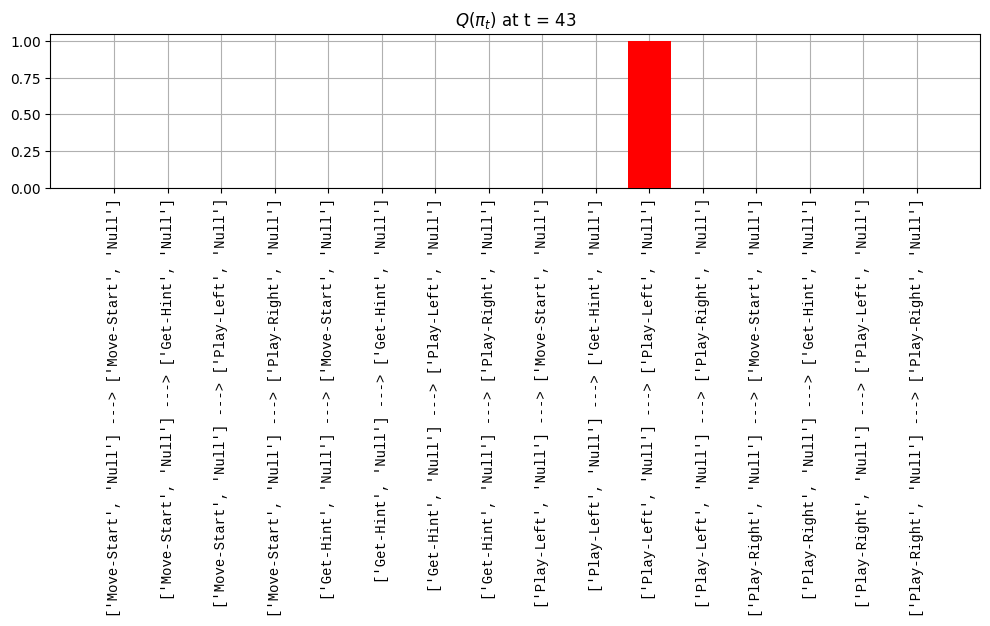

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 43: Play-Left
Context at time 43: Left-Better
Reward at time 43: Null

===================== Time 44: =====================


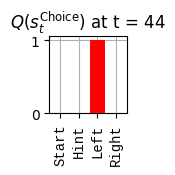

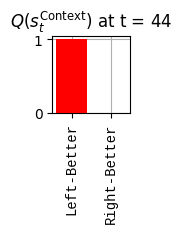

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


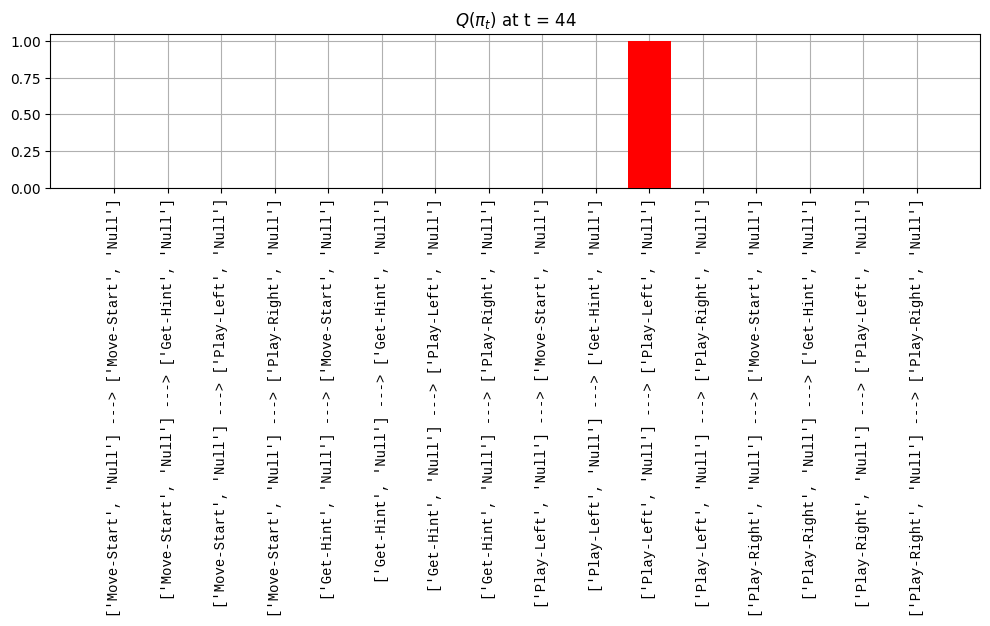

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 44: Play-Left
Context at time 44: Left-Better
Reward at time 44: Null

===================== Time 45: =====================


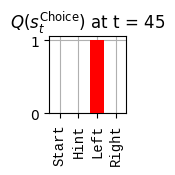

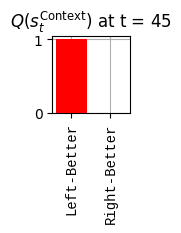

len(EFE)=16
EFE: [-13.01 -13.01  -9.01 -17.01 -13.01 -13.01  -9.01 -17.01  -9.01  -9.01
  -5.01 -13.01 -17.01 -17.01 -13.01 -21.01]
np.argmin(EFE)=np.int64(15)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 15: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


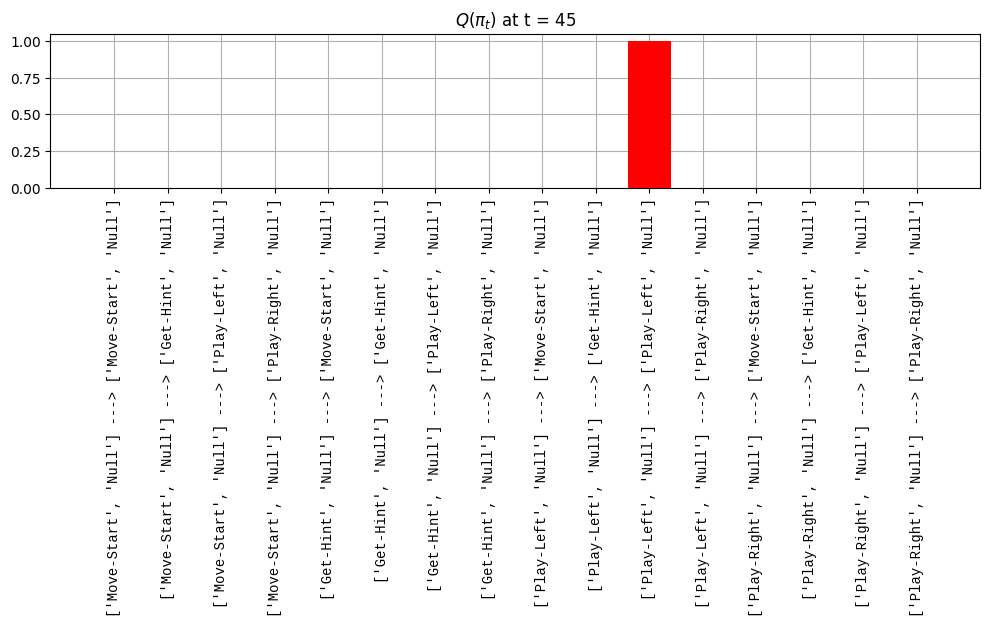

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 45: Play-Left
Context at time 45: Right-Better
Reward at time 45: Null

===================== Time 46: =====================


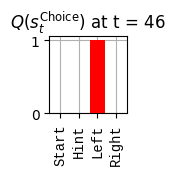

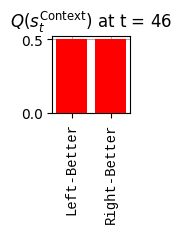

len(EFE)=16
EFE: [-13.01 -12.31 -12.31 -12.31 -12.31 -11.62 -11.62 -11.62 -12.31 -11.62
 -11.62 -11.62 -12.31 -11.62 -11.62 -11.62]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-13.006771679694964)
LOWEST EFE in 0: -13.006771679694964
len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.11 0.11 0.11 0.   0.11 0.11 0.11 0.   0.11
 0.11 0.11]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.11110998083928628)
BEST QIpiI: 0.0


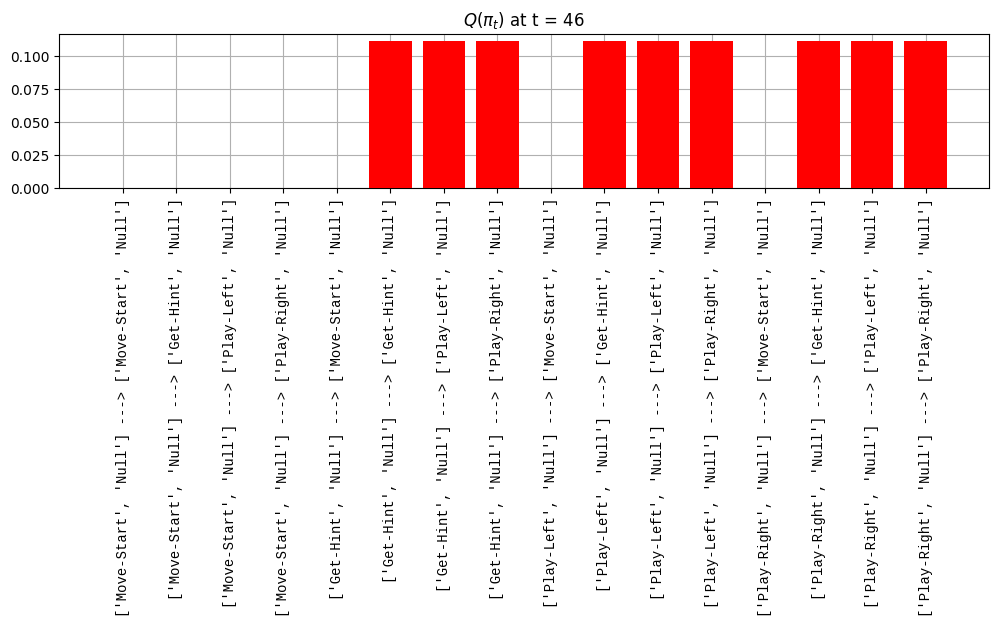

!!!!!!!!!! act_idx=array([2., 0.])
=== step('Play-Left')
Action at time 46: Play-Left
Context at time 46: Right-Better
Reward at time 46: Null

===================== Time 47: =====================


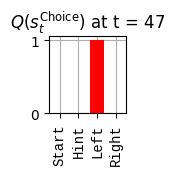

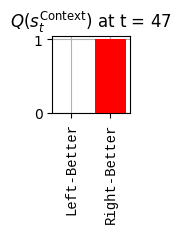

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


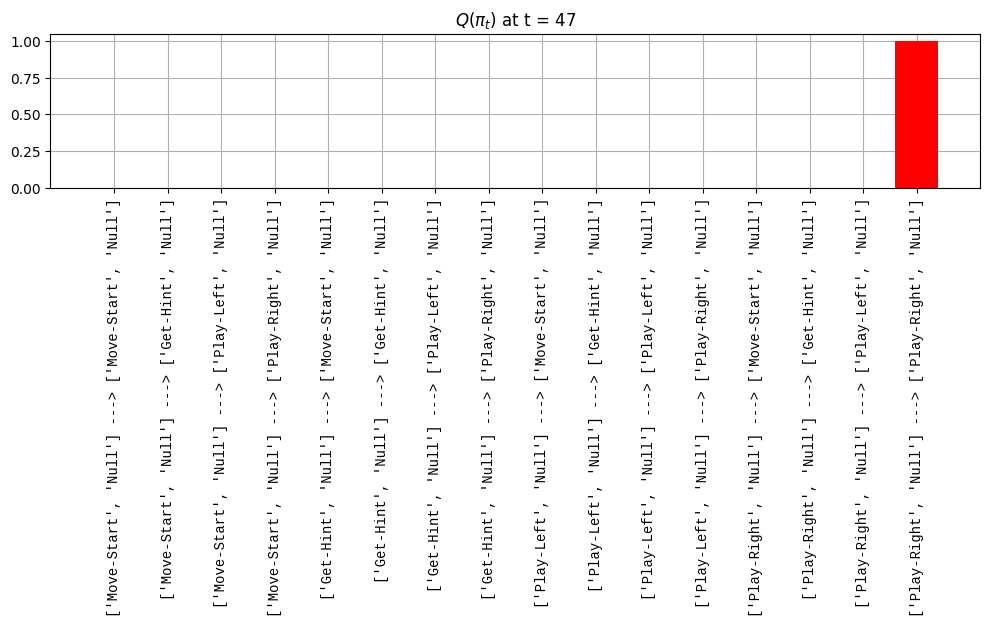

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 47: Play-Right
Context at time 47: Right-Better
Reward at time 47: Null

===================== Time 48: =====================


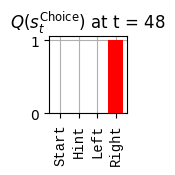

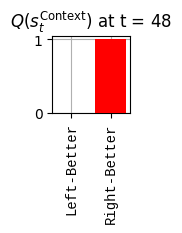

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


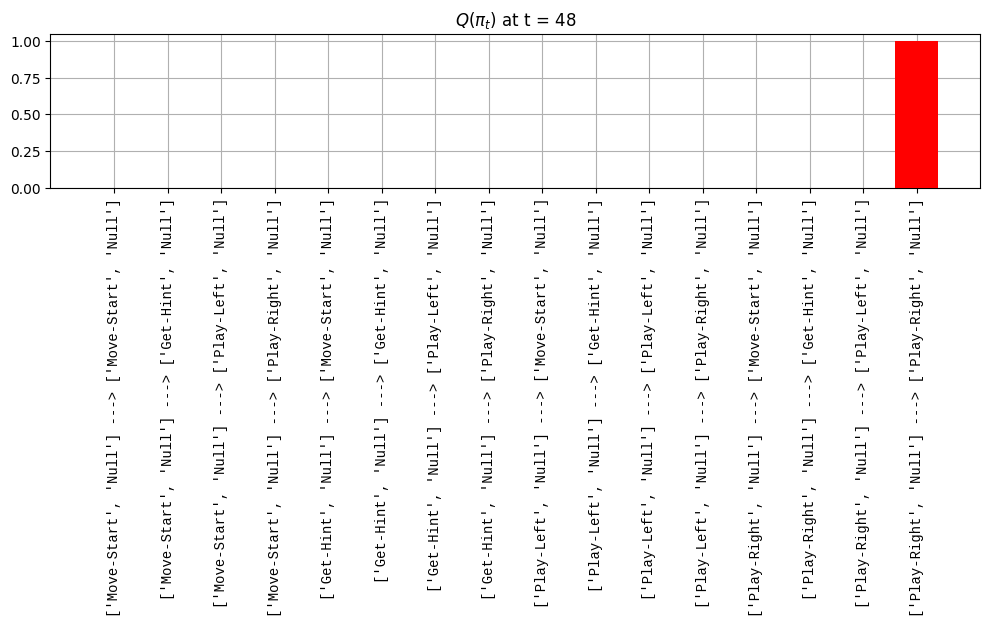

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 48: Play-Right
Context at time 48: Right-Better
Reward at time 48: Null

===================== Time 49: =====================


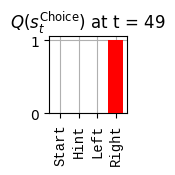

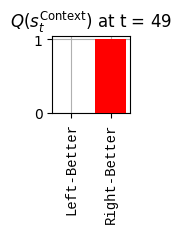

len(EFE)=16
EFE: [-13.01 -13.01 -17.01  -9.01 -13.01 -13.01 -17.01  -9.01 -17.01 -17.01
 -21.01 -13.01  -9.01  -9.01 -13.01  -5.01]
np.argmin(EFE)=np.int64(10)
np.min(EFE)=np.float64(-21.00677167969437)
LOWEST EFE in 10: -21.00677167969437
len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(1.0)
BEST QIpiI: 0.0


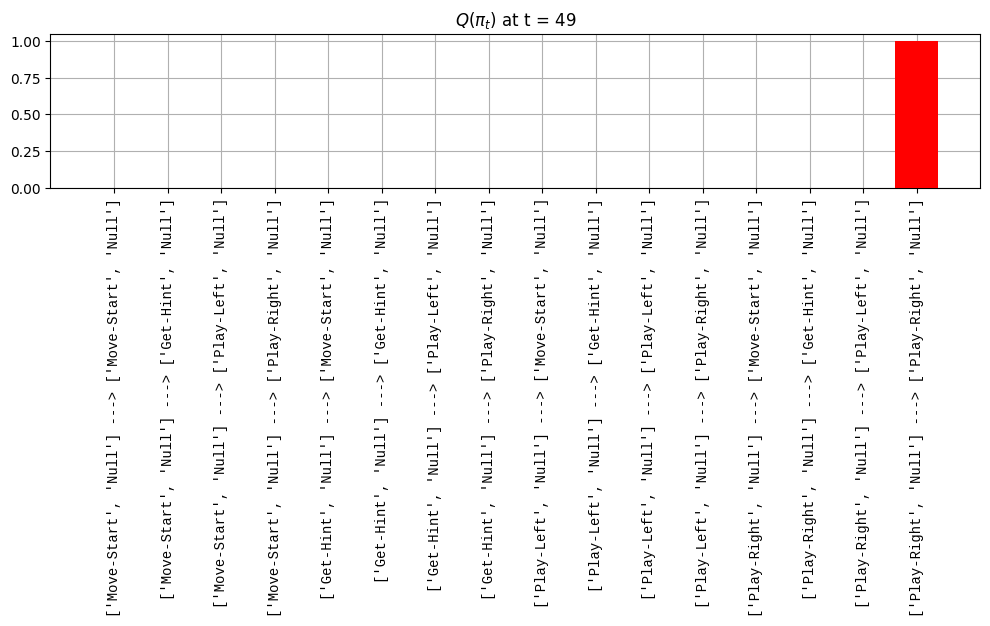

!!!!!!!!!! act_idx=array([3., 0.])
=== step('Play-Right')
Action at time 49: Play-Right
Context at time 49: Right-Better
Reward at time 49: Null


In [58]:
# _T = 5 ## number of timesteps
# _T = 10 ## number of timesteps
# _T = 20 ## number of timesteps
# _T = 40 ## number of timesteps
_T = 50 ## number of timesteps
# _T = 60 ## number of timesteps
assert(len(contexts)==_T)
_a_facs = {'aChoice': [], 'aNull': []}
_s_facs = {'sChoice': [], 'sContext': []}
_s̆_facs = {'s̆Choice': [], 's̆Context': []}
_o_mods = {'oChoice': [], 'oHint': [], 'oRew': []}

## min_F = []
_QIpiIs = []
_EFE = []
## _VFE = []

run_active_inference_loop(_my_agent, _my_envir, T=_T)

In [59]:
# _s_fac_names['sContext']
_s_fac_names[1]

'sContext'

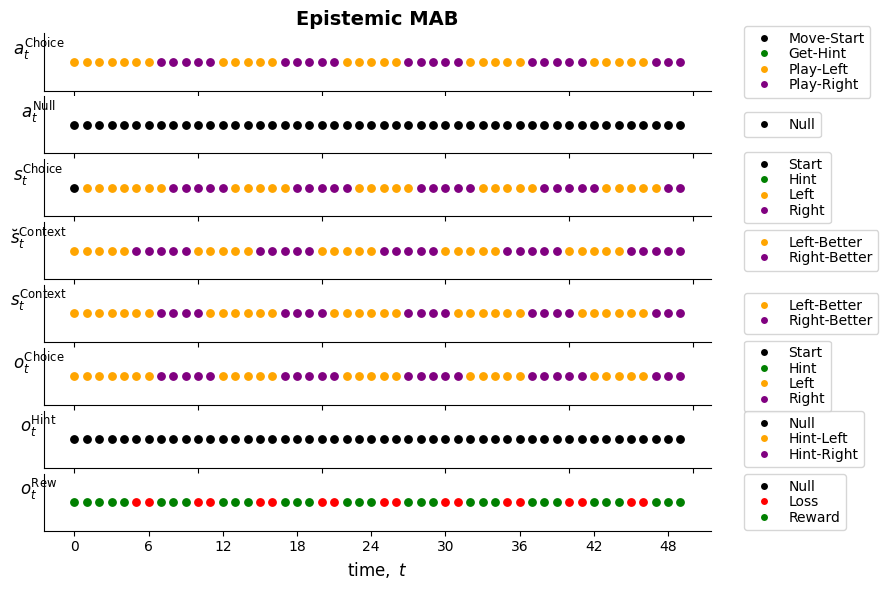

In [60]:
colors = [
{'Move-Start':'black', 'Get-Hint':'green', 'Play-Left': 'orange', 'Play-Right': 'purple'}, ## aChoice
{'Null':'black'}, ## aNull

{'Start':'black', 'Hint':'green', 'Left': 'orange', 'Right': 'purple'}, ## sChoice
{'Left-Better':'orange', 'Right-Better':'purple'}, ## s̆Context
{'Left-Better':'orange', 'Right-Better':'purple'}, ## sContext

{'Start':'black', 'Hint':'green', 'Left': 'orange', 'Right': 'purple'}, ## oChoice
{'Null':'black', 'Hint-Left':'orange', 'Hint-Right':'purple'}, ## oHint
{'Null':'black', 'Loss':'red', 'Reward': 'green'}, ## oRew
]

ylabel_size = 12
# msi = 9 ## markersize for Line2D, diameter in points
msi = 6 ## markersize for Line2D, diameter in points
siz = (msi/2)**2 * np.pi ## size for scatter, area of marker in points squared

fig = plt.figure(figsize=(9, 6))
## gs = GridSpec(6, 1, figure=fig, height_ratios=[1, 3, 1, 3, 3, 1])
# grid_rows = 7
grid_rows = 8
# gs = GridSpec(grid_rows, 1, figure=fig, height_ratios=[1, 1, 1, 1, 1, 1, 1])
gs = GridSpec(grid_rows, 1, figure=fig, height_ratios=[1, 1, 1, 1, 1, 1, 1, 1])
ax = [fig.add_subplot(gs[i]) for i in range(grid_rows)]

i = 0
ax[i].set_title(f'Epistemic MAB', fontweight='bold',fontsize=14)
y_pos = 0
for t, s in zip(range(_T), _a_facs['aChoice']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$a^{\mathrm{Choice}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Move-Start'],markersize=msi,label='Move-Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Get-Hint'],markersize=msi,label='Get-Hint'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Play-Left'],markersize=msi,label='Play-Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Play-Right'],markersize=msi,label='Play-Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 1
y_pos = 0
for t, s in zip(range(_T), _a_facs['aNull']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$a^{\mathrm{Null}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor='black',markersize=msi,label='Null')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 2
y_pos = 0
for t, s in zip(range(_T), _s_facs['sChoice']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$s^{\mathrm{Choice}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Start'],markersize=msi,label='Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint'],markersize=msi,label='Hint'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left'],markersize=msi,label='Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right'],markersize=msi,label='Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 3
y_pos = 0
for t, s in zip(range(_T), _s̆_facs['s̆Context']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s̆^{\mathrm{Context}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left-Better'],markersize=msi,label='Left-Better'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right-Better'],markersize=msi,label='Right-Better')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

# i = 3
i = 4
y_pos = 0
for t, s in zip(range(_T), _s_facs['sContext']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s^{\mathrm{Context}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left-Better'],markersize=msi,label='Left-Better'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right-Better'],markersize=msi,label='Right-Better')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

# i = 4
i = 5
y_pos = 0
for t, s in zip(range(_T), _o_mods['oChoice']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Choice}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Start'],markersize=msi,label='Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint'],markersize=msi,label='Hint'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left'],markersize=msi,label='Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right'],markersize=msi,label='Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

# i = 5
i = 6
y_pos = 0
for t, s in zip(range(_T), _o_mods['oHint']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Hint}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Null'],markersize=msi,label='Null'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint-Left'],markersize=msi,label='Hint-Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint-Right'],markersize=msi,label='Hint-Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

# i = 6
i = 7
y_pos = 0
for t, s in zip(range(_T), _o_mods['oRew']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Rew}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Null'],markersize=msi,label='Null'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Loss'],markersize=msi,label='Loss'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Reward'],markersize=msi,label='Reward')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

ax[i].xaxis.set_major_locator(MaxNLocator(integer=True))
## ax[i].xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))
ax[i].set_xlabel('$\mathrm{time,}\ t$', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.subplots_adjust(hspace=0.1) ## Adjust this value as needed
plt.show()

### 4.6.2 Second evaluation

Now let's try manipulating the agent's prior preferences over reward observations ($\mathbf{C}[1]$) in order to examine the tension between exploration and exploitation.

In [53]:
random.seed(20)

In [54]:
## Create an envir
## re-initialize the environment -- this time, the hint is not always accurate 
##   (`p_hint = 0.8`)
## _my_envir = ThreeArmedBanditEnvir(p_hint=0.8, p_reward=0.8) ##. previously: p_hint=1.0 & p_reward=0.7
_my_envir = EpistemicMABEnvir(
    context="Right-Better", 
    # context="Left-Better", 
    p_hint=0.7,
    p_reward=0.8
) ##. previously: p_hint=1.0 & p_reward=0.7
print(f'Context: {_my_envir.s̆Context}')

Context: Right-Better


In [55]:
## Create an agent
## change the 'shape' of the agent's reward function
## makes the Loss "less aversive" than before (higher prior probability assigned 
##   to seeing the Loss outcome). This should make the agent less 
##   risk-averse / willing to explore both arms, under uncertainty
_C[2][1] = 0.0 ##. previously -4.0 for oRew == 'Loss' observation

## redefine the agent with the new preferences
_my_agent = Agent(
    A=_A, 
    B=_B, 
    C=_C, 
    D=_D,
    ## number of action values (aChoice_1); aNull_0 has a single value, 1*4=4
    # policy_len=1, ##. 4**1 = 4 ele
    policy_len=2,   ##. 4**2 = 16 ele
    # policy_len=3, ##. 4**3 = 64 ele 
    # policy_len=4, ##. 4**4 = 256 ele 
    control_fac_idx=_controllable_indices ##.
)

Re-initialized to:
self.s̆Context='Right-Better'
self.p_hint=0.7
self.p_reward=0.8
oChoice='Start', oHint='Null', oRew='Null'
Number of policies: math.prod(_a_dims)**agt.policy_len=16
	because _a_dims=[4, 1], agt.policy_len=2

===================== Time 0: =====================


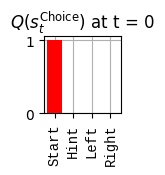

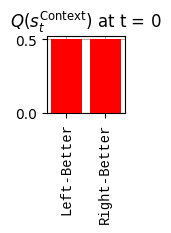

len(EFE)=16
EFE: [-9.45 -9.37 -8.26 -8.26 -9.37 -9.28 -8.17 -8.17 -8.26 -8.17 -7.06 -7.06
 -8.26 -8.17 -7.06 -7.06]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-9.448902606949428)
LOWEST EFE in 0: -9.448902606949428


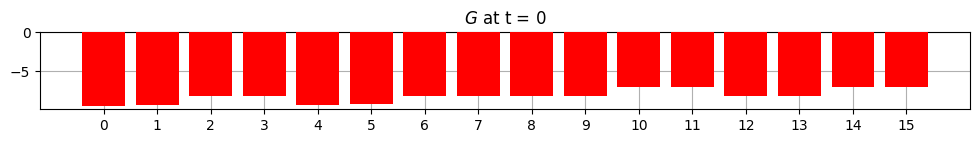

len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.25 0.25 0.   0.
 0.25 0.25]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.2499999939074112)
BEST QIpiI: 0.0


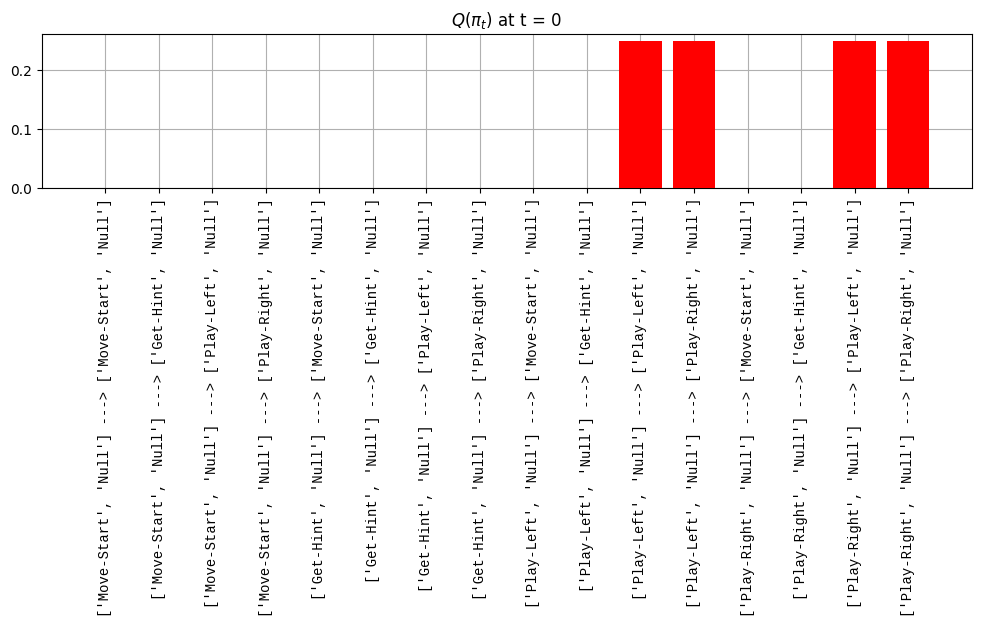

!!!!!!!!!! act_idx=array([2., 0.])
Action at time 0: Play-Left
Reward at time 0: Null

===================== Time 1: =====================


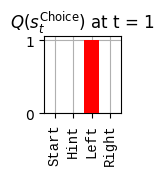

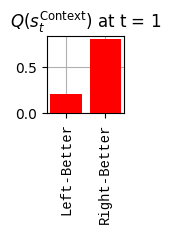

len(EFE)=16
EFE: [-9.45 -9.4  -8.68 -7.96 -9.4  -9.34 -8.63 -7.91 -8.68 -8.63 -7.92 -7.2
 -7.96 -7.91 -7.2  -6.48]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-9.448902606949428)
LOWEST EFE in 0: -9.448902606949428


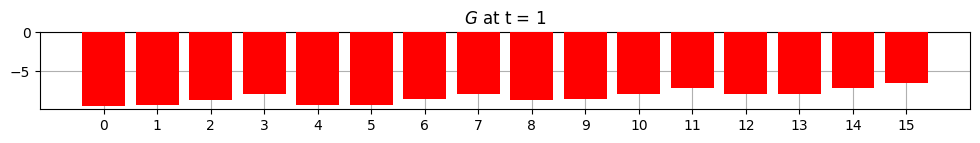

len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.9999801409738043)
BEST QIpiI: 0.0


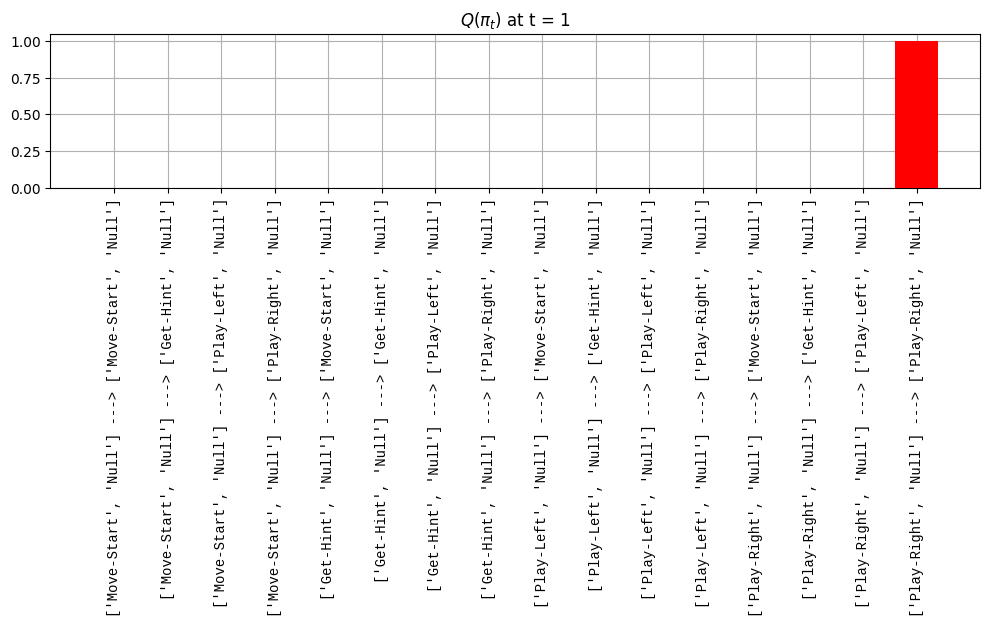

!!!!!!!!!! act_idx=array([3., 0.])
Action at time 1: Play-Right
Reward at time 1: Null

===================== Time 2: =====================


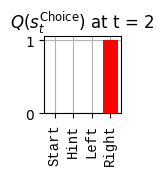

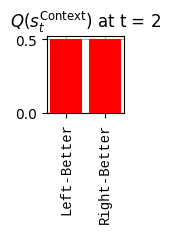

len(EFE)=16
EFE: [-9.45 -9.37 -8.26 -8.26 -9.37 -9.28 -8.17 -8.17 -8.26 -8.17 -7.06 -7.06
 -8.26 -8.17 -7.06 -7.06]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-9.448902606949428)
LOWEST EFE in 0: -9.448902606949428


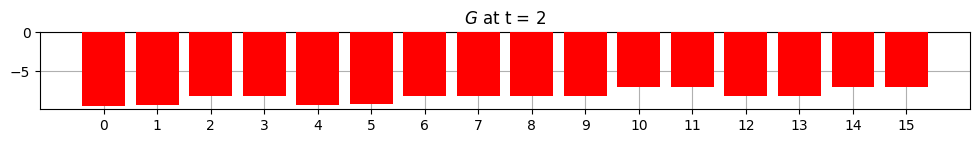

len(QIpiI)=16
QIpiI: [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.25 0.25 0.   0.
 0.25 0.25]
np.argmax(QIpiI)=np.int64(10)
np.max(QIpiI)=np.float64(0.24999999390741298)
BEST QIpiI: 0.0


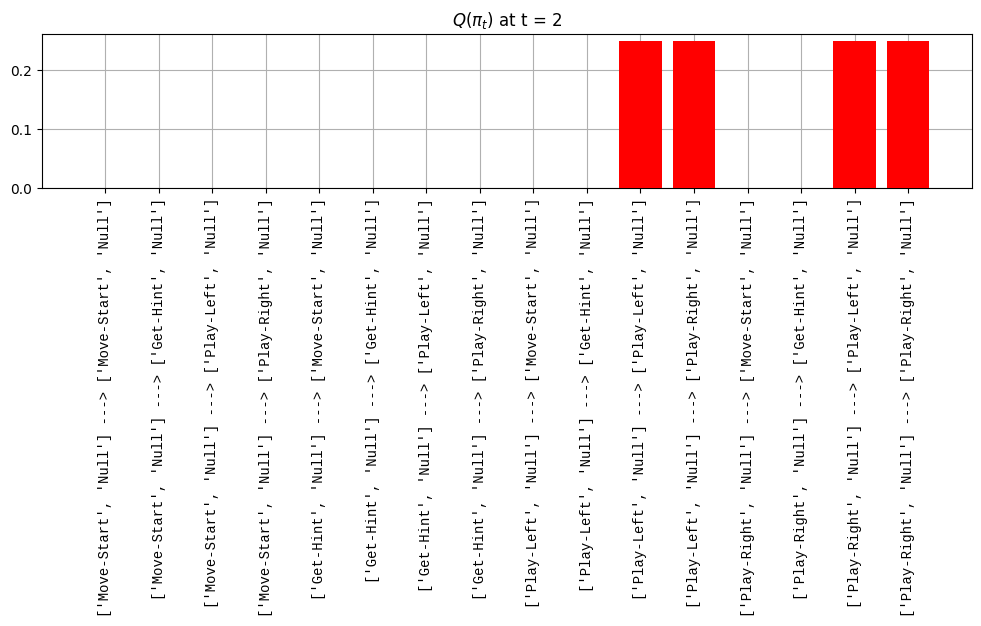

!!!!!!!!!! act_idx=array([2., 0.])
Action at time 2: Play-Left
Reward at time 2: Null

===================== Time 3: =====================


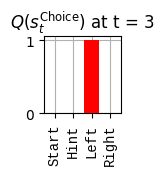

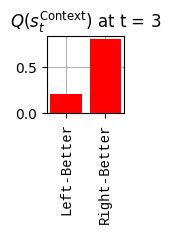

len(EFE)=16
EFE: [-9.45 -9.4  -8.68 -7.96 -9.4  -9.34 -8.63 -7.91 -8.68 -8.63 -7.92 -7.2
 -7.96 -7.91 -7.2  -6.48]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-9.448902606949433)
LOWEST EFE in 0: -9.448902606949433


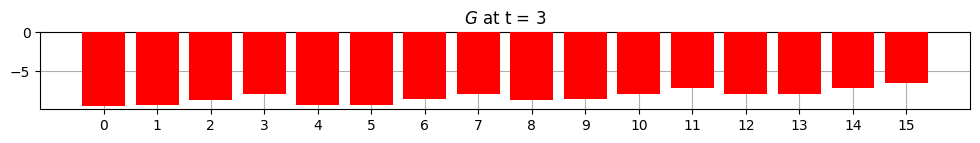

len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.9999801409738043)
BEST QIpiI: 0.0


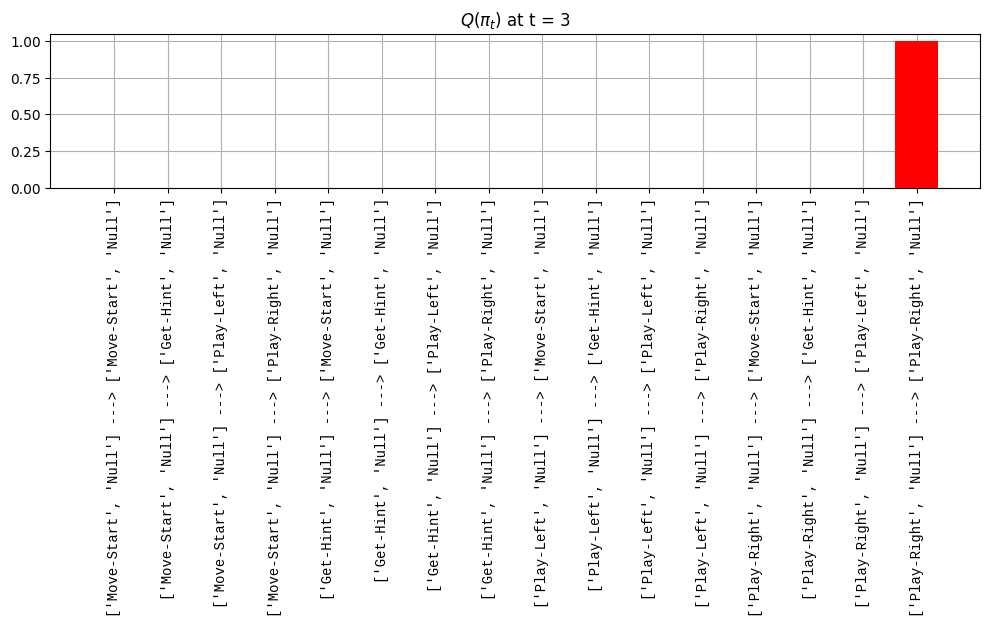

!!!!!!!!!! act_idx=array([3., 0.])
Action at time 3: Play-Right
Reward at time 3: Null

===================== Time 4: =====================


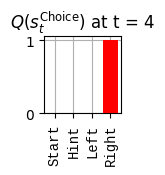

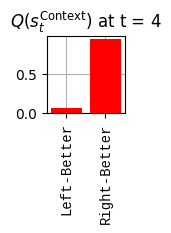

len(EFE)=16
EFE: [-9.45 -9.43 -8.93 -7.87 -9.43 -9.41 -8.91 -7.86 -8.93 -8.91 -8.42 -7.36
 -7.87 -7.86 -7.36 -6.3 ]
np.argmin(EFE)=np.int64(0)
np.min(EFE)=np.float64(-9.448902606949428)
LOWEST EFE in 0: -9.448902606949428


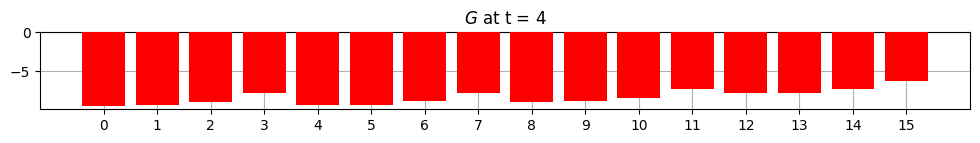

len(QIpiI)=16
QIpiI: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
np.argmax(QIpiI)=np.int64(15)
np.max(QIpiI)=np.float64(0.9999999121309135)
BEST QIpiI: 0.0


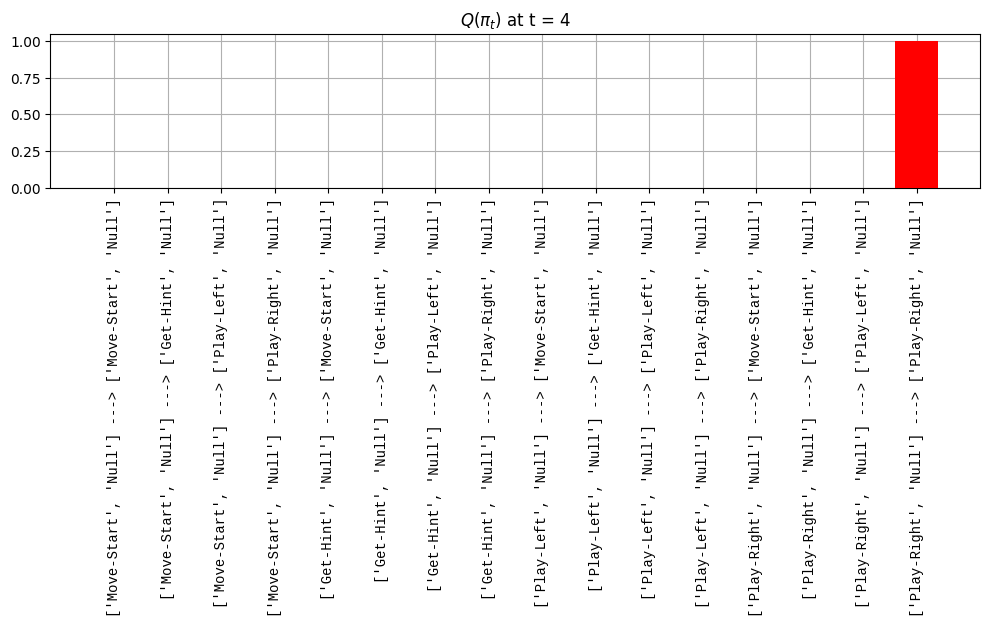

!!!!!!!!!! act_idx=array([3., 0.])
Action at time 4: Play-Right
Reward at time 4: Null


In [56]:
_T = 5 ## number of timesteps

_a_facs = {'aChoice': [], 'aNull': []}
_s_facs = {'sChoice': [], 'sContext': []}
_s̆_facs = {'s̆Choice': [], 's̆Context': []}
_o_mods = {'oChoice': [], 'oHint': [], 'oRew': []}

## min_F = []
_QIpiIs = []
_EFE = []

run_active_inference_loop(_my_agent, _my_envir, T=_T)

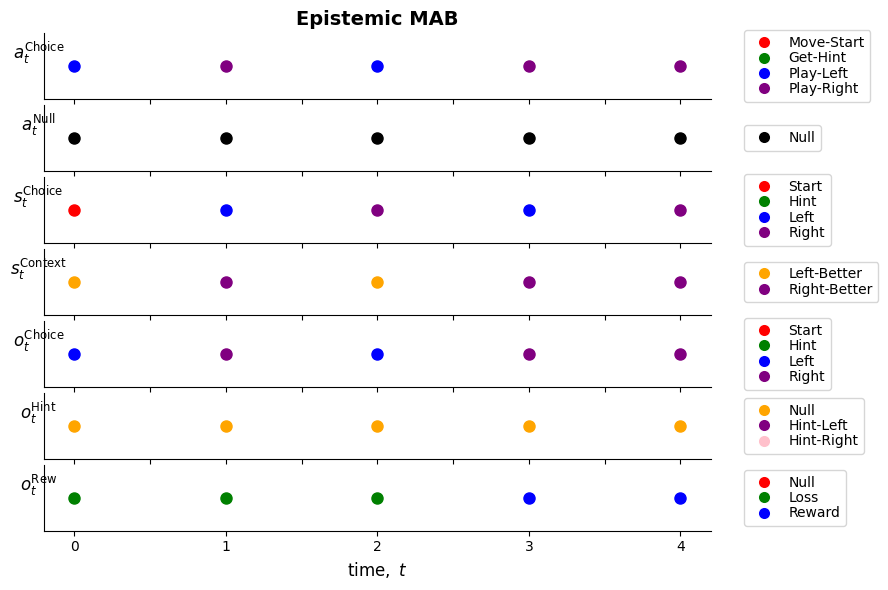

In [57]:
colors = [
{'Move-Start':'red', 'Get-Hint':'green', 'Play-Left': 'blue', 'Play-Right': 'purple'}, ## aChoice
{'Null':'black'}, ## aNull

{'Start':'red', 'Hint':'green', 'Left': 'blue', 'Right': 'purple'}, ## sChoice
{'Left-Better':'orange', 'Right-Better':'purple'}, ## sContext

{'Start':'red', 'Hint':'green', 'Left': 'blue', 'Right': 'purple'}, ## oChoice
{'Null':'orange', 'Hint-Left':'purple', 'Hint-Right':'pink'}, ## oHint
{'Null':'red', 'Loss':'green', 'Reward': 'blue'}, ## oRew
]

ylabel_size = 12
msi = 9 ## markersize for Line2D, diameter in points
siz = (msi/2)**2 * np.pi ## size for scatter, area of marker in points squared

fig = plt.figure(figsize=(9, 6))
## gs = GridSpec(6, 1, figure=fig, height_ratios=[1, 3, 1, 3, 3, 1])
grid_rows = 7
gs = GridSpec(grid_rows, 1, figure=fig, height_ratios=[1, 1, 1, 1, 1, 1, 1])
ax = [fig.add_subplot(gs[i]) for i in range(grid_rows)]

i = 0
ax[i].set_title(f'Epistemic MAB', fontweight='bold',fontsize=14)
y_pos = 0
for t, s in zip(range(_T), _a_facs['aChoice']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$a^{\mathrm{Choice}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Move-Start'],markersize=msi,label='Move-Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Get-Hint'],markersize=msi,label='Get-Hint'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Play-Left'],markersize=msi,label='Play-Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Play-Right'],markersize=msi,label='Play-Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 1
y_pos = 0
for t, s in zip(range(_T), _a_facs['aNull']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$a^{\mathrm{Null}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor='black',markersize=msi,label='Null')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 2
y_pos = 0
for t, s in zip(range(_T), _s_facs['sChoice']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$s^{\mathrm{Choice}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Start'],markersize=msi,label='Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint'],markersize=msi,label='Hint'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left'],markersize=msi,label='Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right'],markersize=msi,label='Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 3
y_pos = 0
for t, s in zip(range(_T), _s_facs['sContext']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s^{\mathrm{Context}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left-Better'],markersize=msi,label='Left-Better'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right-Better'],markersize=msi,label='Right-Better')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 4
y_pos = 0
for t, s in zip(range(_T), _o_mods['oChoice']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Choice}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Start'],markersize=msi,label='Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint'],markersize=msi,label='Hint'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left'],markersize=msi,label='Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right'],markersize=msi,label='Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 5
y_pos = 0
for t, s in zip(range(_T), _o_mods['oHint']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Hint}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Null'],markersize=msi,label='Null'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint-Left'],markersize=msi,label='Hint-Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Hint-Right'],markersize=msi,label='Hint-Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 6
y_pos = 0
for t, s in zip(range(_T), _o_mods['oRew']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Rew}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Null'],markersize=msi,label='Null'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Loss'],markersize=msi,label='Loss'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Reward'],markersize=msi,label='Reward')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

ax[i].xaxis.set_major_locator(MaxNLocator(integer=True))
## ax[i].xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))
ax[i].set_xlabel('$\mathrm{time,}\ t$', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.subplots_adjust(hspace=0.1) ## Adjust this value as needed
plt.show()